# #L929 NAR オッズスナップショット分析 (マージ版) v01

`#L909` (12 桁 netkeiba) と `#L919` (18 桁 楽天) のデータを **両方マージ** して集計するノートブック。

## 対応 race_id
| 桁数 | 形式 | データ提供期間 | sanrentan |
|---|---|---|---|
| 12 桁 | `YYYY VV MMDD RR` | 〜 2026-06-22 (旧 netkeiba 系) | なし |
| 18 桁 | `YYYY MMDD VVVV KK NN RR` | 2026-06-23 〜 (新 楽天 L902) | あり |

## 目的
- 単勝・馬連の **サンプルサイズを最大化** して閾値検証を安定化
- 旧データ (12桁) と新データ (18桁) の傾向差分の可視化
- 3連単は 18桁時代のデータのみで集計

## 分析項目 (#L919 と同等)
1. 取得状況 (日付・桁数別レース数)
2. T-X → T-3 / T-1 オッズ変化率の 10 区分集計
3. 区分別の的中・回収統計 — **単勝・馬連・3連単**
4. 閾値スイープによる最適下落率カットオフ
5. T-3 終端 vs T-2 / T-1 終端 の比較
6. **最適閾値サマリー表** (Tx→Tx 全パターン × 桁数別 ROI/PL 一覧)

In [1]:
import os
import re
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_rows', 200)
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)

# 日本語フォント (Windows)
mpl.rcParams['font.family'] = ['Meiryo', 'Yu Gothic', 'MS Gothic', 'DejaVu Sans']
mpl.rcParams['axes.unicode_minus'] = False

DATA_ROOT = Path('D:/workspace/nar/data')
SNAPSHOT_DIR = DATA_ROOT / 'odds_snapshots'
RESULT_DIR   = DATA_ROOT / 'results'
SHUTSUBA_DIR = DATA_ROOT / 'shutsuba'

# T-label (L902 / L901 v2: T-2 追加済み)
T_LABELS = ['T60', 'T30', 'T15', 'T10', 'T5', 'T3', 'T2', 'T1']
T_OFFSETS = {'T60': 60, 'T30': 30, 'T15': 15, 'T10': 10, 'T5': 5, 'T3': 3, 'T2': 2, 'T1': 1}

# オッズ種別 (Rakuten 内部表記)
KINDS = ['tanfuku', 'umaren', 'sanrentan']

print(f'SNAPSHOT_DIR: {SNAPSHOT_DIR}  (exists={SNAPSHOT_DIR.exists()})')
print(f'RESULT_DIR  : {RESULT_DIR}    (exists={RESULT_DIR.exists()})')
print(f'SHUTSUBA_DIR: {SHUTSUBA_DIR}  (exists={SHUTSUBA_DIR.exists()})')

SNAPSHOT_DIR: D:\workspace\nar\data\odds_snapshots  (exists=True)
RESULT_DIR  : D:\workspace\nar\data\results    (exists=True)
SHUTSUBA_DIR: D:\workspace\nar\data\shutsuba  (exists=True)


## 1. 取得状況の把握

ファイル名形式: `{race_id_12 or 18 digit}_T{XX}_{kind}_{YYYYMMDD-HHMM}.csv`
- 12 桁: `YYYY VV MMDD RR` (旧 netkeiba)
- 18 桁: `YYYY MMDD VVVV KK NN RR` (新 楽天)
- 桁数で race_date / venue_code / race_num の切り出し位置を分岐

In [2]:
def parse_snapshot_filename(p: Path) -> dict | None:
    m = re.match(r'(\d{12}|\d{18})_(T\d+)_(tanfuku|umaren|sanrentan)_(\d{8})-(\d{4})\.csv', p.name)
    if not m:
        return None
    race_id, label, kind, snap_date, snap_hhmm = m.groups()
    digits = len(race_id)
    if digits == 12:
        # 12 桁: YYYY(4) + VV(2) + MMDD(4) + RR(2)
        race_date = f'{race_id[:4]}-{race_id[6:8]}-{race_id[8:10]}'
        venue_code = race_id[4:6]
        race_num = int(race_id[10:12])
    else:
        # 18 桁: YYYY(4) + MMDD(4) + VVVV(4) + KK(2) + NN(2) + RR(2)
        race_date = f'{race_id[:4]}-{race_id[4:6]}-{race_id[6:8]}'
        venue_code = race_id[8:12]
        race_num = int(race_id[16:18])
    return {
        'race_id': race_id,
        'label': label,
        'kind': kind,
        'race_date': race_date,
        'venue_code': venue_code,
        'race_num': race_num,
        'digits': digits,
        'snapshot_at': pd.to_datetime(f'{snap_date}T{snap_hhmm[:2]}:{snap_hhmm[2:]}'),
        'path': p,
    }


snap_records = [r for r in (parse_snapshot_filename(p) for p in SNAPSHOT_DIR.glob('*.csv')) if r]
df_inv = pd.DataFrame(snap_records)
print(f'統合スナップショット: {len(df_inv):,} 件')
if df_inv.empty:
    print('⚠ データなし')
else:
    print(f'対象 race_id 数: {df_inv["race_id"].nunique():,}')
    print(f'対象日           : {sorted(df_inv["race_date"].unique())}')
    print(f'桁数別件数       : {df_inv["digits"].value_counts().to_dict()}')
    print(f'kind 内訳        : {df_inv["kind"].value_counts().to_dict()}')
    # 桁数 × kind クロス
    print('\n=== 桁数 × kind クロス ===')
    print(df_inv.groupby(['digits', 'kind']).size().unstack(fill_value=0))
df_inv.head()

統合スナップショット: 13,015 件
対象 race_id 数: 637
対象日           : ['2026-06-19', '2026-06-20', '2026-06-22', '2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29', '2026-06-30', '2026-07-01', '2026-07-02', '2026-07-03']
桁数別件数       : {18: 11689, 12: 1326}
kind 内訳        : {'tanfuku': 4565, 'umaren': 4548, 'sanrentan': 3902}

=== 桁数 × kind クロス ===
kind    sanrentan  tanfuku  umaren
digits                            
12              0      680     646
18           3902     3885    3902


,race_id,label,kind,race_date,venue_code,race_num,digits,snapshot_at,path
0,202606231106040608,T10,sanrentan,2026-06-23,1106,8,18,2026-06-23 15:29:00,D:\workspace\nar\data\odds_snapshots\202606231...
1,202606231106040608,T10,tanfuku,2026-06-23,1106,8,18,2026-06-23 15:29:00,D:\workspace\nar\data\odds_snapshots\202606231...
2,202606231106040608,T10,umaren,2026-06-23,1106,8,18,2026-06-23 15:29:00,D:\workspace\nar\data\odds_snapshots\202606231...
3,202606231106040608,T15,sanrentan,2026-06-23,1106,8,18,2026-06-23 15:24:00,D:\workspace\nar\data\odds_snapshots\202606231...
4,202606231106040608,T15,tanfuku,2026-06-23,1106,8,18,2026-06-23 15:24:00,D:\workspace\nar\data\odds_snapshots\202606231...


In [3]:
# venue 名を shutsuba CSV から構築 (race_id → venue マッピング)
venue_map = {}
for p in SHUTSUBA_DIR.glob('*_shutsuba.csv'):
    try:
        # 12 桁 or 18 桁
        m = re.match(r'(\d{12}|\d{18})_shutsuba\.csv', p.name)
        if not m:
            continue
        rid = m.group(1)
        df = pd.read_csv(p, encoding='utf-8-sig', nrows=1)
        if 'venue' in df.columns and not df['venue'].empty:
            venue_map[rid] = str(df['venue'].iloc[0])
    except Exception:
        pass
print(f'venue マッピング: {len(venue_map)} race')

if not df_inv.empty:
    df_inv['venue'] = df_inv['race_id'].map(venue_map).fillna('?')
    print(df_inv[['race_id', 'race_date', 'venue', 'label', 'kind']].head(10))

venue マッピング: 646 race
              race_id   race_date venue label       kind
0  202606231106040608  2026-06-23    水沢   T10  sanrentan
1  202606231106040608  2026-06-23    水沢   T10    tanfuku
2  202606231106040608  2026-06-23    水沢   T10     umaren
3  202606231106040608  2026-06-23    水沢   T15  sanrentan
4  202606231106040608  2026-06-23    水沢   T15    tanfuku
5  202606231106040608  2026-06-23    水沢   T15     umaren
6  202606231106040608  2026-06-23    水沢    T5  sanrentan
7  202606231106040608  2026-06-23    水沢    T5    tanfuku
8  202606231106040608  2026-06-23    水沢    T5     umaren
9  202606231106040610  2026-06-23    水沢   T10  sanrentan


In [4]:
# ── 日付 × 場所ごとのレース数 / 日付 × T-label カバレッジ
if not df_inv.empty:
    by_date_venue = (df_inv.groupby(['race_date', 'venue'])['race_id']
                     .nunique().unstack(fill_value=0))
    print('=== 日付×場所 レース数 ===')
    display(by_date_venue.style.background_gradient(cmap='Blues'))

    for kind, cmap in [('tanfuku', 'Blues'), ('umaren', 'Greens'), ('sanrentan', 'Oranges')]:
        cov = (df_inv[df_inv['kind'] == kind]
               .groupby(['race_date', 'label'])['race_id'].nunique()
               .unstack(fill_value=0))
        cov = cov.reindex(columns=T_LABELS, fill_value=0)
        print(f'=== {kind}: 日付×T-label のレース数 ===')
        display(cov.style.background_gradient(cmap=cmap))

=== 日付×場所 レース数 ===


venue,?,佐賀,名古屋,園田,大井,川崎,帯広(ば),帯広ば,水沢,浦和,盛岡,笠松,船橋,金沢,門別,高知
race_date,,,,,,,,,,,,,,,,
2026-06-19,0,0,12,8,0,8,0,0,0,0,0,0,0,0,0,0
2026-06-20,0,12,0,0,0,0,12,0,0,0,0,0,0,0,0,12
2026-06-22,0,0,8,0,0,0,8,0,11,10,0,0,0,11,0,0
2026-06-23,0,0,0,0,0,0,0,0,4,8,0,0,0,6,10,0
2026-06-24,0,0,0,12,0,0,0,0,0,12,0,12,0,0,12,0
2026-06-25,0,11,0,12,0,0,0,0,0,12,0,12,0,0,12,0
2026-06-26,1,0,0,10,0,0,0,0,0,12,0,12,0,0,0,0
2026-06-27,0,11,0,0,0,0,0,12,0,0,0,0,0,0,0,11
2026-06-28,2,0,0,0,0,0,0,12,0,0,12,0,12,9,0,11


=== tanfuku: 日付×T-label のレース数 ===


label,T60,T30,T15,T10,T5,T3,T2,T1
race_date,,,,,,,,
2026-06-19,26,24,24,23,22,22,0,19
2026-06-20,36,36,36,36,36,36,0,35
2026-06-22,43,40,35,37,34,29,17,33
2026-06-23,19,22,23,23,24,23,19,21
2026-06-24,47,48,48,48,48,47,39,43
2026-06-25,57,58,57,57,54,48,46,46
2026-06-26,32,33,32,31,31,29,25,23
2026-06-27,34,34,34,34,34,33,31,29
2026-06-28,56,56,56,56,52,48,55,44


=== umaren: 日付×T-label のレース数 ===


label,T60,T30,T15,T10,T5,T3,T2,T1
race_date,,,,,,,,
2026-06-19,19,19,19,18,18,18,0,15
2026-06-20,36,36,36,36,36,36,0,35
2026-06-22,43,40,35,37,34,29,17,33
2026-06-23,19,22,23,23,24,23,19,21
2026-06-24,46,48,48,48,48,47,39,43
2026-06-25,57,58,57,57,54,48,46,46
2026-06-26,32,33,33,32,32,29,25,23
2026-06-27,34,34,34,34,34,33,31,29
2026-06-28,58,58,58,58,54,50,57,45


=== sanrentan: 日付×T-label のレース数 ===


label,T60,T30,T15,T10,T5,T3,T2,T1
race_date,,,,,,,,
2026-06-23,19,22,23,23,24,23,19,21
2026-06-24,46,48,48,48,48,47,39,43
2026-06-25,57,58,57,57,54,48,46,46
2026-06-26,32,32,33,32,32,29,25,23
2026-06-27,34,34,34,34,34,33,31,29
2026-06-28,58,58,58,58,54,50,57,45
2026-06-29,47,48,48,48,47,45,34,40
2026-06-30,60,60,60,60,58,60,55,49
2026-07-01,47,48,48,48,46,48,48,40


In [5]:
# ── T-X & T-3 / T-X & T-1 が両方揃ったレース数の確認 (有効レース母集団)
if not df_inv.empty:
    rows = []
    for kind in KINDS:
        sub = df_inv[df_inv['kind'] == kind]
        labels_per_race = sub.groupby('race_id')['label'].apply(set)
        n_total = len(labels_per_race)
        rows.append({
            'kind': kind,
            '全レース': n_total,
            'T-10 & T-3 揃い': int((labels_per_race.apply(lambda s: 'T10' in s and 'T3' in s)).sum()),
            'T-10 & T-1 揃い': int((labels_per_race.apply(lambda s: 'T10' in s and 'T1' in s)).sum()),
            'T-3 & T-1 揃い':  int((labels_per_race.apply(lambda s: 'T3' in s and 'T1' in s)).sum()),
        })
    display(pd.DataFrame(rows))

,kind,全レース,T-10 & T-3 揃い,T-10 & T-1 揃い,T-3 & T-1 揃い
0,tanfuku,634,572,492,469
1,umaren,633,569,488,466
2,sanrentan,524,487,407,387


## 2. オッズスナップショット読込

各 kind ごとに wide テーブルを作成。
- `tanfuku`: index=(race_id, umaban), columns=label, values=odds_tan
- `umaren`:  index=(race_id, P1, P2), columns=label, values=odds_umaren
- `sanrentan`: index=(race_id, P1, P2, P3), columns=label, values=odds_sanrentan

In [6]:
def load_snapshots(kind: str, labels: list[str]) -> pd.DataFrame:
    if df_inv.empty:
        return pd.DataFrame()
    target = df_inv[(df_inv['kind'] == kind) & (df_inv['label'].isin(labels))]
    dfs = []
    for p in target['path']:
        try:
            dfs.append(pd.read_csv(p, encoding='utf-8-sig'))
        except Exception as e:
            print(f'  [WARN] {p.name}: {e}')
    if not dfs:
        return pd.DataFrame()
    out = pd.concat(dfs, ignore_index=True)
    # 12 桁 (int) と 18 桁 (str) の merge 衝突回避のため文字列で統一
    out['race_id'] = out['race_id'].astype(str)
    return out


def build_wide(kind: str, labels: list[str]) -> pd.DataFrame:
    '''指定 kind / labels の wide DataFrame を返す。'''
    raw = load_snapshots(kind, labels)
    if raw.empty:
        return pd.DataFrame()
    if kind == 'tanfuku':
        key_cols, odds_col = ['race_id', 'umaban'], 'odds_tan'
    elif kind == 'umaren':
        key_cols, odds_col = ['race_id', 'P1', 'P2'], 'odds_umaren'
    elif kind == 'sanrentan':
        key_cols, odds_col = ['race_id', 'P1', 'P2', 'P3'], 'odds_sanrentan'
    else:
        return pd.DataFrame()
    dedup = (raw.sort_values('snapshot_time')
                .drop_duplicates(key_cols + ['label'], keep='last'))
    wide = (dedup.pivot_table(index=key_cols, columns='label',
                              values=odds_col, aggfunc='last')
                 .reset_index())
    return wide

## 3. 結果・払戻データの結合

`{race_id}_result.csv` から 1着・2着・3着 を、`{race_id}_payout.csv` から
単勝・馬連・**3連単** の払戻を取得。

In [7]:
# ── 結果
res_files = sorted(RESULT_DIR.glob('*_result.csv'))
# 12 桁 or 18 桁
res_files = [p for p in res_files if re.match(r'(\d{12}|\d{18})_result\.csv', p.name)]
res_dfs = [pd.read_csv(p, encoding='utf-8-sig') for p in res_files]
df_res = pd.concat(res_dfs, ignore_index=True) if res_dfs else pd.DataFrame()
if not df_res.empty:
    df_res['race_id'] = df_res['race_id'].astype(str)
print(f'result 行数: {len(df_res):,}  / 対象 race_id: {df_res["race_id"].nunique() if not df_res.empty else 0}')

if not df_res.empty:
    df_res['rank'] = pd.to_numeric(df_res['rank'], errors='coerce').astype('Int64')
    df_res['umaban'] = pd.to_numeric(df_res['umaban'], errors='coerce').astype('Int64')
    df_res_clean = df_res.dropna(subset=['rank', 'umaban'])
    # 同着の重複と複数回 fetch の重複を除外 (同一 race_id × rank は最初の 1 件のみ)
    df_res_clean = df_res_clean.drop_duplicates(subset=['race_id', 'rank'], keep='first')
    # 1着 / 2着 / 3着 馬番を race_id ごとに抽出
    winners = (df_res_clean[df_res_clean['rank'].isin([1, 2, 3])]
                .pivot(index='race_id', columns='rank', values='umaban')
                .rename(columns={1: 'win_1st', 2: 'win_2nd', 3: 'win_3rd'})
                .reset_index())
    print(f'1-3着 揃ったレース: {winners.dropna(subset=["win_1st","win_2nd","win_3rd"]).shape[0]:,}')
else:
    df_res_clean = pd.DataFrame()
    winners = pd.DataFrame()

result 行数: 6,890  / 対象 race_id: 747
1-3着 揃ったレース: 736


In [8]:
# ── 払戻
pay_files = sorted(RESULT_DIR.glob('*_payout.csv'))
pay_files = [p for p in pay_files if re.match(r'(\d{12}|\d{18})_payout\.csv', p.name)]
pay_dfs = [pd.read_csv(p, encoding='utf-8-sig') for p in pay_files]
df_pay = pd.concat(pay_dfs, ignore_index=True) if pay_dfs else pd.DataFrame()
if not df_pay.empty:
    df_pay['race_id'] = df_pay['race_id'].astype(str)
print(f'payout 行数: {len(df_pay):,}')

# 単勝
if not df_pay.empty:
    df_pay_tan = df_pay[df_pay['kenshu'] == '単勝'].copy()
    df_pay_tan['win_umaban'] = pd.to_numeric(df_pay_tan['combo'], errors='coerce').astype('Int64')
    df_pay_tan['payout_tan'] = pd.to_numeric(df_pay_tan['payout'], errors='coerce')
    df_pay_tan = df_pay_tan[['race_id', 'win_umaban', 'payout_tan']]

    # 馬連
    df_pay_uma = df_pay[df_pay['kenshu'] == '馬連'].copy()
    def _parse_uma(c):
        if not isinstance(c, str): return (pd.NA, pd.NA)
        parts = re.findall(r'\d+', c)
        if len(parts) < 2: return (pd.NA, pd.NA)
        return (min(int(parts[0]), int(parts[1])), max(int(parts[0]), int(parts[1])))
    pairs = df_pay_uma['combo'].apply(_parse_uma)
    df_pay_uma['win_P1'] = pairs.apply(lambda t: t[0]).astype('Int64')
    df_pay_uma['win_P2'] = pairs.apply(lambda t: t[1]).astype('Int64')
    df_pay_uma['payout_uma'] = pd.to_numeric(df_pay_uma['payout'], errors='coerce')
    df_pay_uma = df_pay_uma[['race_id', 'win_P1', 'win_P2', 'payout_uma']]

    # 3連単 (combo = "1-10-8" など順序保持)
    df_pay_san = df_pay[df_pay['kenshu'] == '3連単'].copy()
    def _parse_san(c):
        if not isinstance(c, str): return (pd.NA, pd.NA, pd.NA)
        parts = re.findall(r'\d+', c)
        if len(parts) < 3: return (pd.NA, pd.NA, pd.NA)
        return (int(parts[0]), int(parts[1]), int(parts[2]))
    trips = df_pay_san['combo'].apply(_parse_san)
    df_pay_san['win_P1'] = trips.apply(lambda t: t[0]).astype('Int64')
    df_pay_san['win_P2'] = trips.apply(lambda t: t[1]).astype('Int64')
    df_pay_san['win_P3'] = trips.apply(lambda t: t[2]).astype('Int64')
    df_pay_san['payout_san'] = pd.to_numeric(df_pay_san['payout'], errors='coerce')
    df_pay_san = df_pay_san[['race_id', 'win_P1', 'win_P2', 'win_P3', 'payout_san']]

    print(f'単勝 payout: {len(df_pay_tan):,} レース')
    print(f'馬連 payout: {len(df_pay_uma):,} レース')
    print(f'3連単 payout: {len(df_pay_san):,} レース')
else:
    df_pay_tan = df_pay_uma = df_pay_san = pd.DataFrame()

payout 行数: 6,477
単勝 payout: 742 レース
馬連 payout: 742 レース
3連単 payout: 742 レース


## 4. パターン構築関数 (TXX → end_label) — 単勝・馬連・3連単 共通

`build_pattern(start_label, kind, end_label)` で change_rate + hit + payout を返す。
有効レースは (start ∩ end ∩ payout) を動的に計算 (#L909 と同じ方針)。

In [9]:
def build_pattern(start_label: str, kind: str, end_label: str = 'T3') -> pd.DataFrame:
    '''指定 (start, end) の change_rate × hit × payout を返す。'''
    raw = load_snapshots(kind, [start_label, end_label])
    if raw.empty:
        return pd.DataFrame()

    if kind == 'tanfuku':
        key_cols, odds_col = ['race_id', 'umaban'], 'odds_tan'
        pay_df = df_pay_tan.dropna(subset=['win_umaban', 'payout_tan']) if not df_pay_tan.empty else pd.DataFrame()
        pay_col = 'payout_tan'
    elif kind == 'umaren':
        key_cols, odds_col = ['race_id', 'P1', 'P2'], 'odds_umaren'
        pay_df = df_pay_uma.dropna(subset=['win_P1', 'win_P2', 'payout_uma']) if not df_pay_uma.empty else pd.DataFrame()
        pay_col = 'payout_uma'
    elif kind == 'sanrentan':
        key_cols, odds_col = ['race_id', 'P1', 'P2', 'P3'], 'odds_sanrentan'
        pay_df = df_pay_san.dropna(subset=['win_P1', 'win_P2', 'win_P3', 'payout_san']) if not df_pay_san.empty else pd.DataFrame()
        pay_col = 'payout_san'
    else:
        return pd.DataFrame()

    if pay_df.empty:
        return pd.DataFrame()

    # 動的 valid_races
    races_start = set(raw[raw['label'] == start_label]['race_id'])
    races_end   = set(raw[raw['label'] == end_label]['race_id'])
    races_pay   = set(pay_df['race_id'])
    valid_races = races_start & races_end & races_pay
    if not valid_races:
        return pd.DataFrame()

    dedup = (raw.sort_values('snapshot_time')
                .drop_duplicates(key_cols + ['label'], keep='last'))
    wide = (dedup.pivot_table(index=key_cols, columns='label',
                              values=odds_col, aggfunc='last')
                 .reset_index())
    if start_label not in wide.columns or end_label not in wide.columns:
        return pd.DataFrame()
    wide = wide.dropna(subset=[start_label, end_label])
    wide = wide[wide['race_id'].isin(valid_races)]
    wide['change_rate'] = (wide[end_label] - wide[start_label]) / wide[start_label] * 100
    wide = wide[np.isfinite(wide['change_rate'])]

    merged = wide.merge(pay_df, on='race_id', how='inner')
    if kind == 'tanfuku':
        merged['hit'] = (merged['umaban'] == merged['win_umaban']).astype(int)
    elif kind == 'umaren':
        merged['hit'] = ((merged['P1'] == merged['win_P1'])
                         & (merged['P2'] == merged['win_P2'])).astype(int)
    else:  # sanrentan: 順序保持
        merged['hit'] = ((merged['P1'] == merged['win_P1'])
                         & (merged['P2'] == merged['win_P2'])
                         & (merged['P3'] == merged['win_P3'])).astype(int)
    merged['payout'] = np.where(merged['hit'] == 1, merged[pay_col], 0)
    return merged

## 5. 区分集計関数 + 閾値スイープ

In [10]:
def bin_stats(df: pd.DataFrame, value_col: str = 'change_rate', n_bins: int = 10) -> pd.DataFrame:
    sub = df[np.isfinite(df[value_col])].copy()
    if sub.empty:
        return pd.DataFrame()
    sub['bin'] = pd.qcut(sub[value_col], q=n_bins, duplicates='drop')
    agg = (sub.groupby('bin', observed=True)
             .agg(母数=('hit', 'size'),
                  的中数=('hit', 'sum'),
                  回収額=('payout', 'sum'),
                  平均配当=('payout', lambda s: s[s > 0].mean() if (s > 0).any() else np.nan))
             .reset_index())
    agg['区分下限(%)'] = agg['bin'].apply(lambda x: float(x.left)).round(2)
    agg['区分上限(%)'] = agg['bin'].apply(lambda x: float(x.right)).round(2)
    agg['的中率(%)']   = (agg['的中数'] / agg['母数'] * 100).round(2)
    agg['回収率(%)']   = (agg['回収額'] / (agg['母数'] * 100) * 100).round(1)
    agg['平均配当(¥)'] = agg['平均配当'].round(0)
    return agg[['区分下限(%)', '区分上限(%)', '母数', '的中数', '的中率(%)',
                '回収額', '回収率(%)', '平均配当(¥)']]


def style_stats(df: pd.DataFrame):
    def color_rec(v):
        if pd.isna(v): return ''
        if v >= 120: return 'background-color:#2e7d32;color:#fff'
        if v >= 100: return 'background-color:#66bb6a;color:#000'
        if v >=  80: return 'background-color:#a5d6a7;color:#000'
        if v >=  60: return 'background-color:#fff176;color:#000'
        return 'background-color:#e57373;color:#000'

    def color_hit(v):
        if pd.isna(v): return ''
        if v >= 30: return 'background-color:#2e7d32;color:#fff'
        if v >= 20: return 'background-color:#66bb6a;color:#000'
        if v >= 15: return 'background-color:#a5d6a7;color:#000'
        if v >= 10: return 'background-color:#fff176;color:#000'
        return 'background-color:#ef9a9a;color:#000'

    return (df.style
              .map(color_hit, subset=['的中率(%)'])
              .map(color_rec, subset=['回収率(%)'])
              .format({'回収額': '{:,.0f}', '平均配当(¥)': '{:,.0f}'}))


def threshold_sweep(df: pd.DataFrame, thresholds: np.ndarray) -> pd.DataFrame:
    if df.empty:
        return pd.DataFrame()
    rows = []
    for th in thresholds:
        sub = df[df['change_rate'] <= th]
        n = len(sub)
        if n == 0:
            rows.append({'threshold': th, 'n': 0, 'hit_rate': np.nan, 'roi': np.nan, 'pl': 0})
            continue
        rev = sub['payout'].sum()
        rows.append({
            'threshold': th, 'n': n,
            'hit_rate': sub['hit'].sum() / n * 100,
            'roi':  rev / (n * 100) * 100,
            'pl':   int(rev - n * 100),
        })
    return pd.DataFrame(rows)


THRESHOLDS = np.arange(-50, 1, 1.0)
MIN_N = 20
START_LABELS = ['T60', 'T30', 'T15', 'T10', 'T5']

## 6. TXX → T-3 全パターンの集計 (単勝・馬連・**3連単**)

In [11]:
# パターン × kind を一括計算
pat = {kind: {s: build_pattern(s, kind, 'T3') for s in START_LABELS} for kind in KINDS}

summary = pd.DataFrame([
    {
        'pattern': f'{s}→T3',
        **{f'{kind}_n': len(pat[kind][s]) for kind in KINDS},
        **{f'{kind}_的中': int(pat[kind][s]['hit'].sum()) if not pat[kind][s].empty else 0
           for kind in KINDS},
    }
    for s in START_LABELS
])
print('=== TXX → T-3 各パターンの母数 ===')
display(summary)

=== TXX → T-3 各パターンの母数 ===


,pattern,tanfuku_n,umaren_n,sanrentan_n,tanfuku_的中,umaren_的中,sanrentan_的中
0,T60→T3,5316,24744,328415,533,546,464
1,T30→T3,5449,25680,355186,546,562,479
2,T15→T3,5467,25908,377742,548,564,482
3,T10→T3,5492,26030,383362,551,567,484
4,T5→T3,5288,25121,372051,531,548,465


In [12]:
# 各 kind × start_label の 10 区分テーブル
for kind in KINDS:
    print(f'\n========== {kind} ==========')
    for s in START_LABELS:
        df = pat[kind][s]
        if df.empty:
            print(f'  [SKIP] {kind} {s}→T3: データなし')
            continue
        stats = bin_stats(df, 'change_rate', n_bins=10)
        if stats.empty:
            continue
        print(f'=== {kind}: {s} → T-3   n={len(df)} / 的中={int(df["hit"].sum())} ===')
        display(style_stats(stats))


========== tanfuku ==========
=== tanfuku: T60 → T-3   n=5316 / 的中=533 ===


,区分下限(%),区分上限(%),母数,的中数,的中率(%),回収額,回収率(%),平均配当(¥)
0,-100.001000,-50.461000,532,88,16.540000,"36,230",68.100000,412
1,-50.461000,-32.143000,534,82,15.360000,"35,480",66.400000,433
2,-32.143000,-16.414000,529,73,13.800000,"35,540",67.200000,487
3,-16.414000,0.000000,554,99,17.870000,"40,390",72.900000,408
4,0.000000,20.072000,509,62,12.180000,"34,740",68.300000,560
5,20.072000,44.909000,532,49,9.210000,"67,780",127.400000,"1,383"
6,44.909000,82.632000,531,35,6.590000,"41,350",77.900000,"1,181"
7,82.632000,136.773000,532,23,4.320000,"22,810",42.900000,992
8,136.773000,244.540000,531,17,3.200000,"41,770",78.700000,"2,457"
9,244.540000,7930.000000,532,5,0.940000,"8,790",16.500000,"1,758"


=== tanfuku: T30 → T-3   n=5449 / 的中=546 ===


,区分下限(%),区分上限(%),母数,的中数,的中率(%),回収額,回収率(%),平均配当(¥)
0,-100.001000,-45.294000,545,69,12.660000,"26,900",49.400000,390
1,-45.294000,-28.592000,545,80,14.680000,"41,630",76.400000,520
2,-28.592000,-14.034000,545,96,17.610000,"41,820",76.700000,436
3,-14.034000,0.000000,593,90,15.180000,"40,550",68.400000,451
4,0.000000,15.730000,498,62,12.450000,"47,970",96.300000,774
5,15.730000,35.975000,543,59,10.870000,"59,360",109.300000,"1,006"
6,35.975000,65.923000,545,43,7.890000,"41,930",76.900000,975
7,65.923000,108.333000,545,23,4.220000,"36,720",67.400000,"1,597"
8,108.333000,175.020000,545,14,2.570000,"16,710",30.700000,"1,194"
9,175.020000,5990.000000,545,10,1.830000,"15,080",27.700000,"1,508"


=== tanfuku: T15 → T-3   n=5467 / 的中=548 ===


...

,区分下限(%),区分上限(%),母数,的中数,的中率(%),回収額,回収率(%),平均配当(¥)
0,-93.384000,-24.559000,37775,60,0.160000,"1,889,240",50.000000,"31,487"
1,-24.559000,-10.693000,37781,115,0.300000,"5,422,300",143.500000,"47,150"
2,-10.693000,-1.190000,37767,109,0.290000,"3,345,400",88.600000,"30,692"
3,-1.190000,7.241000,37774,74,0.200000,"2,778,940",73.600000,"37,553"
4,7.241000,16.467000,37777,42,0.110000,"1,947,380",51.500000,"46,366"
5,16.467000,27.703000,37771,30,0.080000,"828,990",21.900000,"27,633"
6,27.703000,42.941000,37774,32,0.080000,"3,607,140",95.500000,"112,723"
7,42.941000,64.929000,37819,10,0.030000,"549,830",14.500000,"54,983"
8,64.929000,105.658000,37729,7,0.020000,"2,011,900",53.300000,"287,414"
9,105.658000,1087.898000,37775,3,0.010000,"2,503,360",66.300000,"834,453"


=== sanrentan: T10 → T-3   n=383362 / 的中=484 ===


,区分下限(%),区分上限(%),母数,的中数,的中率(%),回収額,回収率(%),平均配当(¥)
0,-94.017000,-19.248000,38366,49,0.130000,"4,523,940",117.900000,"92,325"
1,-19.248000,-7.860000,38307,125,0.330000,"2,204,600",57.600000,"17,637"
2,-7.860000,-0.916000,38336,95,0.250000,"3,624,080",94.500000,"38,148"
3,-0.916000,4.957000,38338,76,0.200000,"2,292,950",59.800000,"30,170"
4,4.957000,11.095000,38334,46,0.120000,"1,161,020",30.300000,"25,240"
5,11.095000,18.381000,38341,45,0.120000,"3,288,390",85.800000,"73,075"
6,18.381000,27.769000,38332,29,0.080000,"3,527,080",92.000000,"121,623"
7,27.769000,41.115000,38338,10,0.030000,"749,120",19.500000,"74,912"
8,41.115000,64.249000,38333,8,0.020000,"2,455,740",64.100000,"306,968"
9,64.249000,869.495000,38337,1,0.000000,"1,325,340",34.600000,"1,325,340"


=== sanrentan: T5 → T-3   n=372051 / 的中=465 ===


,区分下限(%),区分上限(%),母数,的中数,的中率(%),回収額,回収率(%),平均配当(¥)
0,-93.764000,-8.257000,37210,41,0.110000,"1,542,360",41.500000,"37,619"
1,-8.257000,-2.494000,37201,98,0.260000,"6,507,330",174.900000,"66,401"
2,-2.494000,0.113000,37205,117,0.310000,"2,516,780",67.600000,"21,511"
3,0.113000,1.468000,37205,68,0.180000,"2,791,680",75.000000,"41,054"
4,1.468000,3.259000,37205,50,0.130000,"2,457,660",66.100000,"49,153"
5,3.259000,5.436000,37205,40,0.110000,"2,000,250",53.800000,"50,006"
6,5.436000,8.443000,37204,18,0.050000,"2,208,160",59.400000,"122,676"
7,8.443000,13.135000,37210,24,0.060000,"1,516,630",40.800000,"63,193"
8,13.135000,18.970000,37202,6,0.020000,"858,820",23.100000,"143,137"
9,18.970000,389.543000,37204,3,0.010000,"1,128,020",30.300000,"376,007"


## 7. 閾値スイープ + 最適閾値 (kind 別)

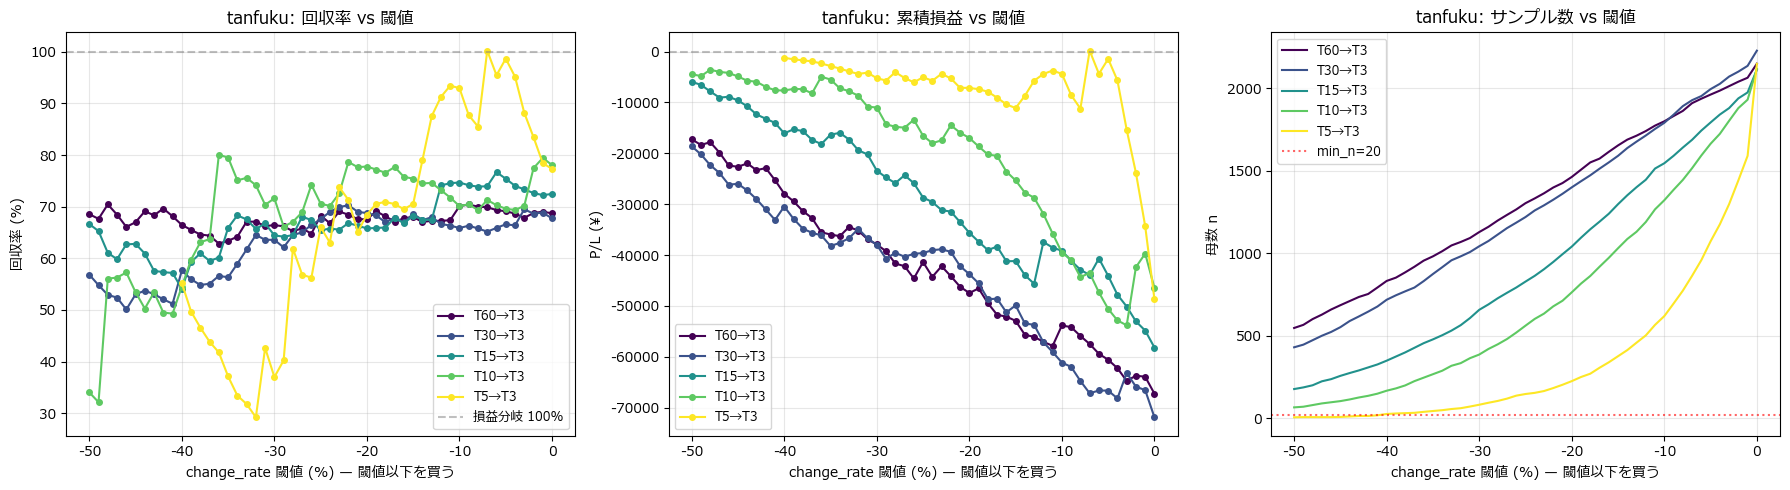

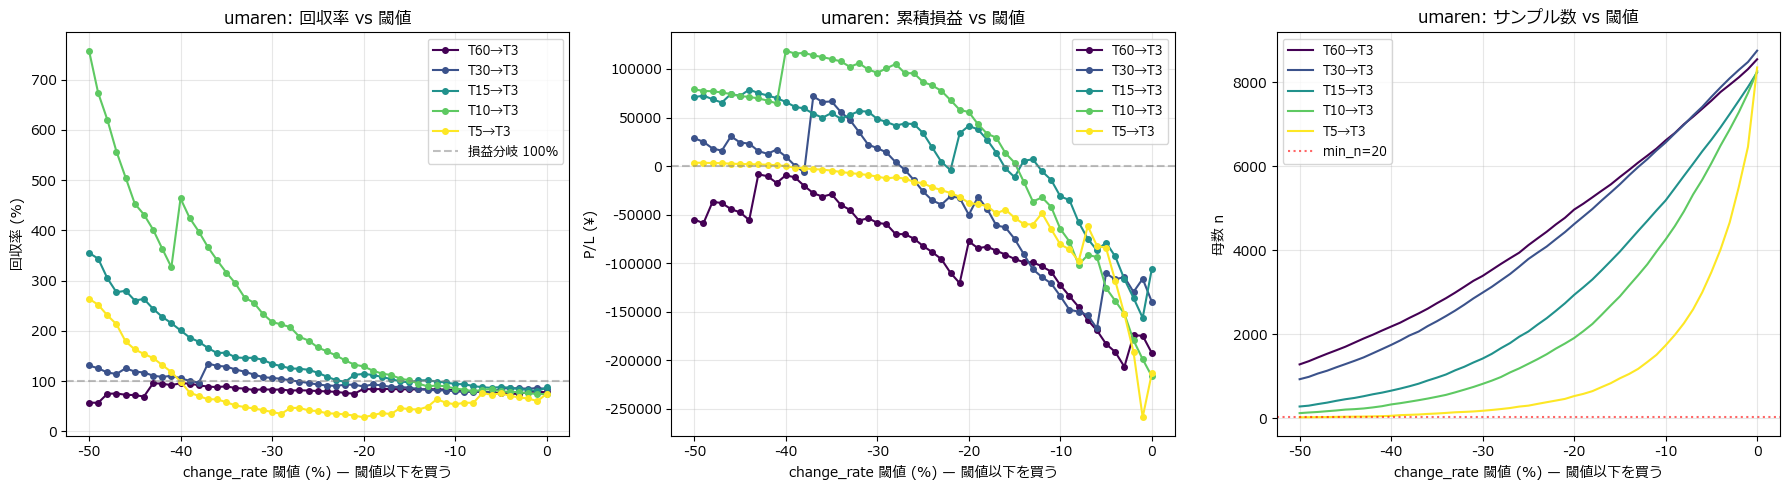

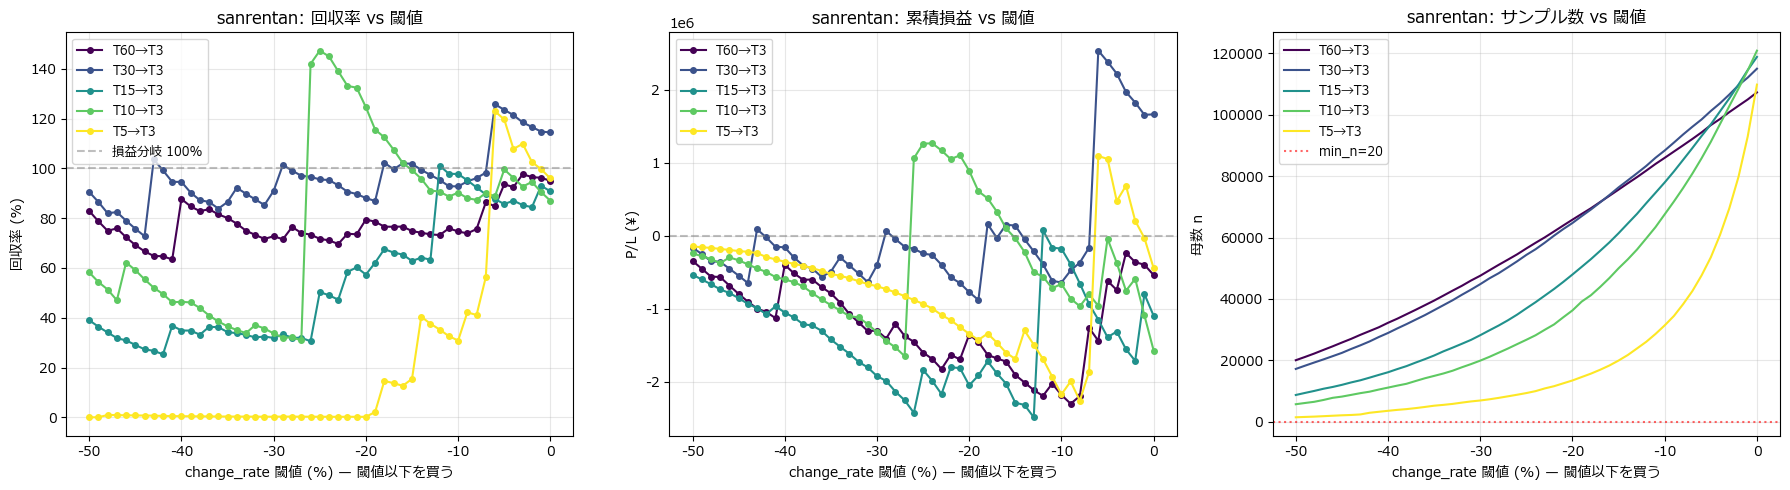

In [13]:
sweep = {kind: {s: threshold_sweep(pat[kind][s], THRESHOLDS) for s in START_LABELS}
         for kind in KINDS}


def plot_sweep(sweeps: dict, title_prefix: str, end_label: str = 'T3', min_n: int = 20):
    cmap = plt.colormaps['viridis']
    colors = [cmap(i / max(1, len(START_LABELS) - 1)) for i in range(len(START_LABELS))]
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    ax_roi, ax_pl, ax_n = axes

    for color, start in zip(colors, START_LABELS):
        s = sweeps.get(start, pd.DataFrame())
        if s.empty:
            continue
        ok = s['n'] >= min_n
        tag = f'{start}→{end_label}'
        ax_roi.plot(s.loc[ok, 'threshold'], s.loc[ok, 'roi'], 'o-', color=color, label=tag, ms=4)
        ax_pl .plot(s.loc[ok, 'threshold'], s.loc[ok, 'pl'],  'o-', color=color, label=tag, ms=4)
        ax_n  .plot(s['threshold'], s['n'], '-', color=color, label=tag)

    ax_roi.axhline(100, color='gray', linestyle='--', alpha=0.5, label='損益分岐 100%')
    ax_pl.axhline(0, color='gray', linestyle='--', alpha=0.5)
    ax_n.axhline(min_n, color='red', linestyle=':', alpha=0.6, label=f'min_n={min_n}')

    for ax, ylabel, title in [
        (ax_roi, '回収率 (%)', f'{title_prefix}: 回収率 vs 閾値'),
        (ax_pl,  'P/L (¥)',    f'{title_prefix}: 累積損益 vs 閾値'),
        (ax_n,   '母数 n',     f'{title_prefix}: サンプル数 vs 閾値'),
    ]:
        ax.set_xlabel('change_rate 閾値 (%) — 閾値以下を買う')
        ax.set_ylabel(ylabel)
        ax.set_title(title)
        ax.legend(loc='best', fontsize=9)
        ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


for kind in KINDS:
    plot_sweep(sweep[kind], kind, end_label='T3', min_n=MIN_N)

In [14]:
def best_thresholds(sweeps: dict, min_n: int = 20, end_label: str = 'T3') -> pd.DataFrame:
    rows = []
    for start, s in sweeps.items():
        if s.empty:
            continue
        ok = s[(s['n'] >= min_n) & s['roi'].notna()]
        if ok.empty:
            continue
        best_roi = ok.loc[ok['roi'].idxmax()]
        best_pl  = ok.loc[ok['pl'].idxmax()]
        rows.append({
            'pattern': f'{start}→{end_label}',
            '[ROI最大] 閾値(%)':  float(best_roi['threshold']),
            '[ROI最大] 母数':      int(best_roi['n']),
            '[ROI最大] 的中率(%)': round(float(best_roi['hit_rate']), 2),
            '[ROI最大] 回収率(%)': round(float(best_roi['roi']), 1),
            '[ROI最大] P/L(¥)':    int(best_roi['pl']),
            '[PL最大] 閾値(%)':   float(best_pl['threshold']),
            '[PL最大] 母数':       int(best_pl['n']),
            '[PL最大] 的中率(%)':  round(float(best_pl['hit_rate']), 2),
            '[PL最大] 回収率(%)':  round(float(best_pl['roi']), 1),
            '[PL最大] P/L(¥)':     int(best_pl['pl']),
        })
    return pd.DataFrame(rows)


for kind in KINDS:
    bt = best_thresholds(sweep[kind], min_n=MIN_N, end_label='T3')
    print(f'\n=== {kind}: パターン別 最適閾値 (T-3 終端, min_n={MIN_N}) ===')
    display(bt)


=== tanfuku: パターン別 最適閾値 (T-3 終端, min_n=20) ===


,pattern,[ROI最大] 閾値(%),[ROI最大] 母数,[ROI最大] 的中率(%),[ROI最大] 回収率(%),[ROI最大] P/L(¥),[PL最大] 閾値(%),[PL最大] 母数,[PL最大] 的中率(%),[PL最大] 回収率(%),[PL最大] P/L(¥)
0,T60→T3,-48.0,602,16.11,70.4,-17800,-50.0,548,16.79,68.5,-17240
1,T30→T3,-22.0,1325,15.40,70.3,-39370,-50.0,431,13.92,56.8,-18610
2,T15→T3,-6.0,1744,15.08,76.7,-40680,-50.0,178,13.48,66.6,-5940
3,T10→T3,-36.0,247,13.36,80.0,-4930,-48.0,81,7.41,56.0,-3560
4,T5→T3,-7.0,864,14.93,100.2,190,-7.0,864,14.93,100.2,190



=== umaren: パターン別 最適閾値 (T-3 終端, min_n=20) ===


,pattern,[ROI最大] 閾値(%),[ROI最大] 母数,[ROI最大] 的中率(%),[ROI最大] 回収率(%),[ROI最大] P/L(¥),[PL最大] 閾値(%),[PL最大] 母数,[PL最大] 的中率(%),[PL最大] 回収率(%),[PL最大] P/L(¥)
0,T60→T3,-40.0,2182,4.49,95.7,-9420,-43.0,1898,4.11,95.5,-8450
1,T30→T3,-37.0,2063,4.41,134.8,71790,-37.0,2063,4.41,134.8,71790
2,T15→T3,-50.0,278,2.88,355.2,70940,-44.0,482,3.53,263.4,78760
3,T10→T3,-50.0,120,3.33,757.7,78920,-40.0,327,3.67,463.5,118850
4,T5→T3,-50.0,21,4.76,263.8,3440,-50.0,21,4.76,263.8,3440



=== sanrentan: パターン別 最適閾値 (T-3 終端, min_n=20) ===


,pattern,[ROI最大] 閾値(%),[ROI最大] 母数,[ROI最大] 的中率(%),[ROI最大] 回収率(%),[ROI最大] P/L(¥),[PL最大] 閾値(%),[PL最大] 母数,[PL最大] 的中率(%),[PL最大] 回収率(%),[PL最大] P/L(¥)
0,T60→T3,-3.0,100834,0.30,97.7,-234450,-3.0,100834,0.30,97.7,-234450
1,T30→T3,-6.0,98468,0.29,125.8,2535680,-6.0,98468,0.29,125.8,2535680
2,T15→T3,-12.0,71191,0.23,101.1,77570,-12.0,71191,0.23,101.1,77570
3,T10→T3,-25.0,26688,0.10,147.3,1262800,-24.0,28164,0.11,145.0,1267340
4,T5→T3,-6.0,47671,0.13,122.9,1093440,-6.0,47671,0.13,122.9,1093440


## 8. 終端を T-1 / T-2 に変えた検証

L902 (= 楽天) は T-2 も取得しているため、`T-2` 終端も比較対象に加える。

In [15]:
END_LABELS_OTHER = ['T2', 'T1']
START_LABELS_T1 = ['T60', 'T30', 'T15', 'T10', 'T5', 'T3']
START_LABELS_T2 = ['T60', 'T30', 'T15', 'T10', 'T5', 'T3']

pat_other = {
    end_lbl: {
        kind: {s: build_pattern(s, kind, end_lbl) for s in (START_LABELS_T1 if end_lbl == 'T1' else START_LABELS_T2)}
        for kind in KINDS
    }
    for end_lbl in END_LABELS_OTHER
}

sweep_other = {
    end_lbl: {
        kind: {s: threshold_sweep(pat_other[end_lbl][kind][s], THRESHOLDS)
               for s in pat_other[end_lbl][kind]}
        for kind in KINDS
    }
    for end_lbl in END_LABELS_OTHER
}

for end_lbl in END_LABELS_OTHER:
    print(f'\n############ 終端 = {end_lbl} ############')
    for kind in KINDS:
        bt = best_thresholds(sweep_other[end_lbl][kind], min_n=MIN_N, end_label=end_lbl)
        print(f'\n=== {kind}: 最適閾値 ({end_lbl} 終端) ===')
        display(bt)


############ 終端 = T2 ############

=== tanfuku: 最適閾値 (T2 終端) ===


,pattern,[ROI最大] 閾値(%),[ROI最大] 母数,[ROI最大] 的中率(%),[ROI最大] 回収率(%),[ROI最大] P/L(¥),[PL最大] 閾値(%),[PL最大] 母数,[PL最大] 的中率(%),[PL最大] 回収率(%),[PL最大] P/L(¥)
0,T60→T2,-45.0,567,16.23,73.4,-15100,-50.0,451,17.07,71.4,-12920
1,T30→T2,-9.0,1496,16.18,71.6,-42540,-50.0,352,13.07,55.8,-15550
2,T15→T2,-16.0,1020,14.02,68.2,-32440,-50.0,135,14.81,66.8,-4480
3,T10→T2,-1.0,1568,14.99,67.1,-51580,-50.0,59,6.78,37.6,-3680
4,T5→T2,0.0,1625,16.68,77.8,-36050,-42.0,23,4.35,15.2,-1950
5,T3→T2,-23.0,90,8.89,92.6,-670,-23.0,90,8.89,92.6,-670



=== umaren: 最適閾値 (T2 終端) ===


,pattern,[ROI最大] 閾値(%),[ROI最大] 母数,[ROI最大] 的中率(%),[ROI最大] 回収率(%),[ROI最大] P/L(¥),[PL最大] 閾値(%),[PL最大] 母数,[PL最大] 的中率(%),[PL最大] 回収率(%),[PL最大] P/L(¥)
0,T60→T2,-35.0,2228,5.21,96.5,-7720,-35.0,2228,5.21,96.5,-7720
1,T30→T2,-50.0,708,3.81,155.3,39160,-50.0,708,3.81,155.3,39160
2,T15→T2,-50.0,189,3.70,99.5,-90,-50.0,189,3.70,99.5,-90
3,T10→T2,-35.0,467,4.71,177.4,36140,-35.0,467,4.71,177.4,36140
4,T5→T2,0.0,6438,3.99,69.4,-196740,-50.0,35,2.86,17.1,-2900
5,T3→T2,-31.0,111,1.80,448.5,38680,-31.0,111,1.80,448.5,38680



=== sanrentan: 最適閾値 (T2 終端) ===


...

,pattern,[ROI最大] 閾値(%),[ROI最大] 母数,[ROI最大] 的中率(%),[ROI最大] 回収率(%),[ROI最大] P/L(¥),[PL最大] 閾値(%),[PL最大] 母数,[PL最大] 的中率(%),[PL最大] 回収率(%),[PL最大] P/L(¥)
0,T60→T1,-33.0,854,16.86,76.5,-20030,-50.0,458,18.12,67.5,-14880
1,T30→T1,-8.0,1536,16.47,74.9,-38550,-50.0,373,15.01,57.0,-16030
2,T15→T1,-14.0,1145,15.90,76.1,-27340,-50.0,190,14.21,56.5,-8270
3,T10→T1,-1.0,1590,16.35,77.6,-35610,-45.0,143,13.29,74.3,-3670
4,T5→T1,-47.0,56,12.50,96.2,-210,-47.0,56,12.50,96.2,-210
5,T3→T1,-24.0,230,11.74,129.0,6680,-24.0,230,11.74,129.0,6680



=== umaren: 最適閾値 (T1 終端) ===


,pattern,[ROI最大] 閾値(%),[ROI最大] 母数,[ROI最大] 的中率(%),[ROI最大] 回収率(%),[ROI最大] P/L(¥),[PL最大] 閾値(%),[PL最大] 母数,[PL最大] 的中率(%),[PL最大] 回収率(%),[PL最大] P/L(¥)
0,T60→T1,-14.0,4811,4.99,75.8,-116400,-49.0,1142,4.73,72.3,-31680
1,T30→T1,-50.0,853,4.69,87.1,-10970,-50.0,853,4.69,87.1,-10970
2,T15→T1,-39.0,778,5.91,202.8,80010,-34.0,1128,5.94,172.6,81880
3,T10→T1,-16.0,2711,5.09,113.0,35360,-16.0,2711,5.09,113.0,35360
4,T5→T1,-18.0,1481,4.66,83.7,-24120,-50.0,107,5.61,76.0,-2570
5,T3→T1,-21.0,926,4.32,129.4,27220,-21.0,926,4.32,129.4,27220



=== sanrentan: 最適閾値 (T1 終端) ===


,pattern,[ROI最大] 閾値(%),[ROI最大] 母数,[ROI最大] 的中率(%),[ROI最大] 回収率(%),[ROI最大] P/L(¥),[PL最大] 閾値(%),[PL最大] 母数,[PL最大] 的中率(%),[PL最大] 回収率(%),[PL最大] P/L(¥)
0,T60→T1,-36.0,33012,0.36,116.3,537180,-36.0,33012,0.36,116.3,537180
1,T30→T1,-26.0,45379,0.33,100.3,11530,-26.0,45379,0.33,100.3,11530
2,T15→T1,-27.0,33215,0.26,74.8,-837660,-46.0,12795,0.21,67.8,-411820
3,T10→T1,-50.0,8258,0.22,100.2,1820,-50.0,8258,0.22,100.2,1820
4,T5→T1,-29.0,16940,0.22,117.3,293690,-23.0,23006,0.26,114.3,328200
5,T3→T1,-30.0,13957,0.22,98.7,-17790,-30.0,13957,0.22,98.7,-17790


## 9. 終端 T-3 / T-2 / T-1 比較 (kind 別)

同じ start_label で終端だけ変えたときの 最適 P/L を横並びで比較。

In [16]:
def compare_endpoints_3way(kind: str) -> pd.DataFrame:
    bt_t3 = best_thresholds(sweep[kind],       min_n=MIN_N, end_label='T3')
    bt_t2 = best_thresholds(sweep_other['T2'][kind], min_n=MIN_N, end_label='T2')
    bt_t1 = best_thresholds(sweep_other['T1'][kind], min_n=MIN_N, end_label='T1')

    def _start(p): return p.split('→')[0]
    def _index(df): return df.assign(start=df['pattern'].apply(_start)).set_index('start') if not df.empty else df

    t3, t2, t1 = _index(bt_t3), _index(bt_t2), _index(bt_t1)
    starts = sorted(set(t3.index) | set(t2.index) | set(t1.index),
                    key=lambda s: int(s.lstrip('T')), reverse=True)
    rows = []
    for s in starts:
        row = {'start': s}
        for tag, src in [('T3', t3), ('T2', t2), ('T1', t1)]:
            if s in src.index:
                row[f'{tag}:閾値(%)']  = src.loc[s, '[PL最大] 閾値(%)']
                row[f'{tag}:母数']     = int(src.loc[s, '[PL最大] 母数'])
                row[f'{tag}:回収率(%)']= src.loc[s, '[PL最大] 回収率(%)']
                row[f'{tag}:P/L(¥)']  = int(src.loc[s, '[PL最大] P/L(¥)'])
            else:
                row[f'{tag}:閾値(%)']  = np.nan
                row[f'{tag}:母数']     = 0
                row[f'{tag}:回収率(%)']= np.nan
                row[f'{tag}:P/L(¥)']  = 0
        rows.append(row)
    return pd.DataFrame(rows)


for kind in KINDS:
    print(f'\n=== {kind}: T-3 / T-2 / T-1 終端 最適 P/L 比較 ===')
    display(compare_endpoints_3way(kind))


=== tanfuku: T-3 / T-2 / T-1 終端 最適 P/L 比較 ===


,start,T3:閾値(%),T3:母数,T3:回収率(%),T3:P/L(¥),T2:閾値(%),T2:母数,T2:回収率(%),T2:P/L(¥),T1:閾値(%),T1:母数,T1:回収率(%),T1:P/L(¥)
0,T60,-50.0,548,68.5,-17240,-50.0,451,71.4,-12920,-50.0,458,67.5,-14880
1,T30,-50.0,431,56.8,-18610,-50.0,352,55.8,-15550,-50.0,373,57.0,-16030
2,T15,-50.0,178,66.6,-5940,-50.0,135,66.8,-4480,-50.0,190,56.5,-8270
3,T10,-48.0,81,56.0,-3560,-50.0,59,37.6,-3680,-45.0,143,74.3,-3670
4,T5,-7.0,864,100.2,190,-42.0,23,15.2,-1950,-47.0,56,96.2,-210
5,T3,NaN,0,NaN,0,-23.0,90,92.6,-670,-24.0,230,129.0,6680



=== umaren: T-3 / T-2 / T-1 終端 最適 P/L 比較 ===


,start,T3:閾値(%),T3:母数,T3:回収率(%),T3:P/L(¥),T2:閾値(%),T2:母数,T2:回収率(%),T2:P/L(¥),T1:閾値(%),T1:母数,T1:回収率(%),T1:P/L(¥)
0,T60,-43.0,1898,95.5,-8450,-35.0,2228,96.5,-7720,-49.0,1142,72.3,-31680
1,T30,-37.0,2063,134.8,71790,-50.0,708,155.3,39160,-50.0,853,87.1,-10970
2,T15,-44.0,482,263.4,78760,-50.0,189,99.5,-90,-34.0,1128,172.6,81880
3,T10,-40.0,327,463.5,118850,-35.0,467,177.4,36140,-16.0,2711,113.0,35360
4,T5,-50.0,21,263.8,3440,-50.0,35,17.1,-2900,-50.0,107,76.0,-2570
5,T3,NaN,0,NaN,0,-31.0,111,448.5,38680,-21.0,926,129.4,27220



=== sanrentan: T-3 / T-2 / T-1 終端 最適 P/L 比較 ===


,start,T3:閾値(%),T3:母数,T3:回収率(%),T3:P/L(¥),T2:閾値(%),T2:母数,T2:回収率(%),T2:P/L(¥),T1:閾値(%),T1:母数,T1:回収率(%),T1:P/L(¥)
0,T60,-3.0,100834,97.7,-234450,-49.0,19704,85.4,-286920,-36.0,33012,116.3,537180
1,T30,-6.0,98468,125.8,2535680,-50.0,15989,91.4,-137070,-26.0,45379,100.3,11530
2,T15,-12.0,71191,101.1,77570,-50.0,8481,36.8,-535890,-46.0,12795,67.8,-411820
3,T10,-24.0,28164,145.0,1267340,-19.0,39330,103.7,146380,-50.0,8258,100.2,1820
4,T5,-6.0,47671,122.9,1093440,-50.0,2392,0.0,-239200,-23.0,23006,114.3,328200
5,T3,NaN,0,NaN,0,-50.0,1101,0.0,-110100,-30.0,13957,98.7,-17790


## 10. 3連単 独自の特性分析

3連単は組合せ数が圧倒的に多い (馬数×(馬数-1)×(馬数-2)) ため、ベース的中率は 1% 未満になる。
このセクションでは 3連単に固有の問題 (高配当・低的中率) を確認する。

In [17]:
# 3連単の閾値別 回収率 / 平均配当の特性を確認
san_pat_t3 = pat.get('sanrentan', {})
all_rows = []
for s, df in san_pat_t3.items():
    if df.empty:
        continue
    df = df.copy()
    df['start_label'] = s
    all_rows.append(df)
if all_rows:
    san_all = pd.concat(all_rows, ignore_index=True)
    print(f'3連単 全パターン累計: {len(san_all):,} 行 / {san_all["race_id"].nunique()} レース')
    print('=== 全体統計 ===')
    print(f'  ベース的中率: {san_all["hit"].mean() * 100:.3f} %')
    print(f'  ベース回収率: {san_all["payout"].sum() / (len(san_all) * 100) * 100:.1f} %')
    print(f'  的中時の平均配当: {san_all.loc[san_all["hit"]==1, "payout"].mean():.0f} ¥' if (san_all['hit']==1).any() else '  (的中ゼロ)')

    # 閾値別 ROI 推移 (start_label を集約)
    bins_threshold = [-50, -40, -30, -20, -10, -5, 0, 5, 10, 20, 30, 50, 100, 1000]
    san_all['change_bin'] = pd.cut(san_all['change_rate'], bins=bins_threshold)
    agg = (san_all.groupby('change_bin', observed=True)
                 .agg(母数=('hit', 'size'),
                      的中数=('hit', 'sum'),
                      回収額=('payout', 'sum'),
                      平均配当=('payout', lambda s: s[s>0].mean() if (s>0).any() else np.nan))
                 .reset_index())
    agg['的中率(%)'] = (agg['的中数'] / agg['母数'] * 100).round(3)
    agg['回収率(%)'] = (agg['回収額'] / (agg['母数'] * 100) * 100).round(1)
    print('\n=== 3連単 全 start_label 集約 change_rate ビン別 ===')
    display(agg)
else:
    print('3連単データなし')

3連単 全パターン累計: 1,816,756 行 / 486 レース
=== 全体統計 ===
  ベース的中率: 0.131 %
  ベース回収率: 66.3 %
  的中時の平均配当: 50716 ¥

=== 3連単 全 start_label 集約 change_rate ビン別 ===


,change_bin,母数,的中数,回収額,平均配当,的中率(%),回収率(%)
0,"(-50, -40]",38832,76,2750980.0,36197.105263,0.196,70.8
1,"(-40, -30]",55453,138,2468970.0,17891.086957,0.249,44.5
2,"(-30, -20]",80863,223,9093950.0,40780.044843,0.276,112.5
3,"(-20, -10]",122993,347,11099450.0,31986.887608,0.282,90.2
4,"(-10, -5]",88245,248,16039610.0,64675.846774,0.281,181.8
5,"(-5, 0]",132322,349,9857560.0,28245.157593,0.264,74.5
6,"(0, 5]",185047,301,12850600.0,42693.023256,0.163,69.4
7,"(5, 10]",134239,148,5295410.0,35779.797297,0.110,39.4
8,"(10, 20]",198167,165,9427370.0,57135.575758,0.083,47.6
9,"(20, 30]",127993,95,10563660.0,111196.421053,0.074,82.5


## 11. 最適閾値サマリー一覧 (Tx→Tx 全パターン)

統合データ (12+18桁) で **単勝・馬連** の全 Tx→Tx パターン × 最適閾値 を一覧化。
- ROI 順 / PL 順 でソート
- `min_n=30` 以上のサンプル数を持つパターンのみ表示
- T10→T3 ベースラインを別途表示

In [18]:
T_MIN = {'T60':60,'T30':30,'T15':15,'T10':10,'T5':5,'T3':3,'T2':2,'T1':1}
START_PAIRS = ['T60', 'T30', 'T15', 'T10', 'T5', 'T3', 'T2']
END_PAIRS   = ['T30', 'T15', 'T10', 'T5', 'T3', 'T2', 'T1']
MIN_N_SUMMARY = 30


def _best_one(df: pd.DataFrame, thresholds: np.ndarray, min_n: int):
    if df.empty:
        return None
    rows = []
    for th in thresholds:
        sub = df[df['change_rate'] <= th]
        n = len(sub)
        if n == 0:
            continue
        rev = sub['payout'].sum()
        nr = sub['race_id'].nunique()
        rows.append({
            'th': th, 'n': n,
            'hit%': sub['hit'].sum() / n * 100,
            'roi%': rev / (n * 100) * 100,
            'pl': int(rev - n * 100),
            'pick/R': n / max(1, nr),
        })
    sw = pd.DataFrame(rows)
    ok = sw[sw['n'] >= min_n]
    if ok.empty:
        return None
    return {
        'roi': ok.loc[ok['roi%'].idxmax()].to_dict(),
        'pl':  ok.loc[ok['pl'].idxmax()].to_dict(),
    }


def summary_table(kind: str) -> pd.DataFrame:
    rows = []
    for s in START_PAIRS:
        for e in END_PAIRS:
            if T_MIN[s] <= T_MIN[e]:
                continue
            df = build_pattern(s, kind, e)
            if df.empty:
                continue
            r = _best_one(df, THRESHOLDS, MIN_N_SUMMARY)
            if r is None:
                continue
            br, bp = r['roi'], r['pl']
            rows.append({
                'pattern': f'{s}→{e}',
                '母数': len(df),
                'レース数': df['race_id'].nunique(),
                'ROI最大_閾値%': round(br['th'], 1),
                'ROI最大_母数': int(br['n']),
                'ROI最大_的中率%': round(br['hit%'], 2),
                'ROI最大_回収率%': round(br['roi%'], 1),
                'ROI最大_P/L¥': int(br['pl']),
                'ROI最大_買い目/R': round(br['pick/R'], 2),
                'PL最大_閾値%': round(bp['th'], 1),
                'PL最大_母数': int(bp['n']),
                'PL最大_的中率%': round(bp['hit%'], 2),
                'PL最大_回収率%': round(bp['roi%'], 1),
                'PL最大_P/L¥': int(bp['pl']),
                'PL最大_買い目/R': round(bp['pick/R'], 2),
            })
    return pd.DataFrame(rows)


def style_summary(df: pd.DataFrame):
    def cr(v):
        if pd.isna(v): return ''
        if v >= 150: return 'background-color:#1b5e20;color:#fff'
        if v >= 120: return 'background-color:#2e7d32;color:#fff'
        if v >= 100: return 'background-color:#66bb6a;color:#000'
        if v >=  80: return 'background-color:#fff176;color:#000'
        return 'background-color:#e57373;color:#000'

    def hit(v):
        if pd.isna(v): return ''
        if v >= 20: return 'background-color:#66bb6a;color:#000'
        if v >= 15: return 'background-color:#a5d6a7;color:#000'
        if v >= 10: return 'background-color:#fff176;color:#000'
        return 'background-color:#ef9a9a;color:#000'

    return (df.style
              .map(cr,  subset=['ROI最大_回収率%', 'PL最大_回収率%'])
              .map(hit, subset=['ROI最大_的中率%', 'PL最大_的中率%'])
              .format({'ROI最大_P/L¥': '{:,d}', 'PL最大_P/L¥': '{:,d}', '母数': '{:,d}'}))


for kind in ['tanfuku', 'umaren']:
    print(f'\n=========== {kind}: 全 Tx→Tx 最適閾値 (min_n={MIN_N_SUMMARY}) ===========')
    bt = summary_table(kind)
    if bt.empty:
        print('  データなし')
        continue
    # ROI 順
    print(f'--- {kind}: ROI 最大 順 (上位 10) ---')
    display(style_summary(bt.sort_values('ROI最大_回収率%', ascending=False).head(10).reset_index(drop=True)))
    # PL 順
    print(f'--- {kind}: P/L 最大 順 (上位 10) ---')
    display(style_summary(bt.sort_values('PL最大_P/L¥', ascending=False).head(10).reset_index(drop=True)))
    # T10→T3 行
    base = bt[bt['pattern'] == 'T10→T3']
    if not base.empty:
        print(f'--- {kind}: 参考 T10→T3 ベースライン ---')
        display(style_summary(base.reset_index(drop=True)))


=========== tanfuku: 全 Tx→Tx 最適閾値 (min_n=30) ===========
--- tanfuku: ROI 最大 順 (上位 10) ---


,pattern,母数,レース数,ROI最大_閾値%,ROI最大_母数,ROI最大_的中率%,ROI最大_回収率%,ROI最大_P/L¥,ROI最大_買い目/R,PL最大_閾値%,PL最大_母数,PL最大_的中率%,PL最大_回収率%,PL最大_P/L¥,PL最大_買い目/R
0,T2→T1,"3,677",369,-32.000000,94,12.770000,142.400000,"3,990",1.400000,-21.000000,184,11.960000,125.200000,"4,630",1.640000
1,T3→T1,"4,511",467,-24.000000,230,11.740000,129.000000,"6,680",1.530000,-24.000000,230,11.740000,129.000000,"6,680",1.530000
2,T5→T3,"5,288",548,-7.000000,864,14.930000,100.200000,190,1.990000,-7.000000,864,14.930000,100.200000,190,1.990000
3,T10→T5,"5,561",577,-43.000000,103,10.680000,99.400000,-60,1.240000,-43.000000,103,10.680000,99.400000,-60,1.240000
4,T5→T1,"4,545",472,-47.000000,56,12.500000,96.200000,-210,1.330000,-47.000000,56,12.500000,96.200000,-210,1.330000
5,T3→T2,"4,413",444,-23.000000,90,8.890000,92.600000,-670,1.230000,-23.000000,90,8.890000,92.600000,-670,1.230000
6,T30→T15,"5,724",592,-18.000000,1509,12.990000,90.400000,"-14,440",2.720000,-44.000000,498,11.650000,88.300000,"-5,830",1.670000
7,T15→T10,"5,760",596,-35.000000,304,10.530000,84.600000,"-4,670",1.450000,-44.000000,146,8.900000,75.200000,"-3,620",1.290000
8,T60→T15,"5,574",578,-33.000000,1066,13.700000,81.000000,"-20,220",2.180000,-42.000000,750,13.600000,77.100000,"-17,170",1.820000
9,T10→T3,"5,492",568,-36.000000,247,13.360000,80.000000,"-4,930",1.370000,-48.000000,81,7.410000,56.000000,"-3,560",1.330000


--- tanfuku: P/L 最大 順 (上位 10) ---


,pattern,母数,レース数,ROI最大_閾値%,ROI最大_母数,ROI最大_的中率%,ROI最大_回収率%,ROI最大_P/L¥,ROI最大_買い目/R,PL最大_閾値%,PL最大_母数,PL最大_的中率%,PL最大_回収率%,PL最大_P/L¥,PL最大_買い目/R
0,T3→T1,"4,511",467,-24.000000,230,11.740000,129.000000,"6,680",1.530000,-24.000000,230,11.740000,129.000000,"6,680",1.530000
1,T2→T1,"3,677",369,-32.000000,94,12.770000,142.400000,"3,990",1.400000,-21.000000,184,11.960000,125.200000,"4,630",1.640000
2,T5→T3,"5,288",548,-7.000000,864,14.930000,100.200000,190,1.990000,-7.000000,864,14.930000,100.200000,190,1.990000
3,T10→T5,"5,561",577,-43.000000,103,10.680000,99.400000,-60,1.240000,-43.000000,103,10.680000,99.400000,-60,1.240000
4,T5→T1,"4,545",472,-47.000000,56,12.500000,96.200000,-210,1.330000,-47.000000,56,12.500000,96.200000,-210,1.330000
5,T3→T2,"4,413",444,-23.000000,90,8.890000,92.600000,-670,1.230000,-23.000000,90,8.890000,92.600000,-670,1.230000
6,T5→T2,"4,467",451,0.000000,1625,16.680000,77.800000,"-36,050",3.600000,-39.000000,35,2.860000,10.000000,"-3,150",1.130000
7,T10→T3,"5,492",568,-36.000000,247,13.360000,80.000000,"-4,930",1.370000,-48.000000,81,7.410000,56.000000,"-3,560",1.330000
8,T15→T10,"5,760",596,-35.000000,304,10.530000,84.600000,"-4,670",1.450000,-44.000000,146,8.900000,75.200000,"-3,620",1.290000
9,T10→T1,"4,733",490,-1.000000,1590,16.350000,77.600000,"-35,610",3.270000,-45.000000,143,13.290000,74.300000,"-3,670",1.290000


--- tanfuku: 参考 T10→T3 ベースライン ---


...

,pattern,母数,レース数,ROI最大_閾値%,ROI最大_母数,ROI最大_的中率%,ROI最大_回収率%,ROI最大_P/L¥,ROI最大_買い目/R,PL最大_閾値%,PL最大_母数,PL最大_的中率%,PL最大_回収率%,PL最大_P/L¥,PL最大_買い目/R
0,T10→T5,"26,356",576,-50.000000,117,2.560000,774.900000,"78,960",1.520000,-35.000000,432,2.080000,354.800000,"110,080",2.130000
1,T10→T3,"26,030",567,-50.000000,120,3.330000,757.700000,"78,920",1.360000,-40.000000,327,3.670000,463.500000,"118,850",1.820000
2,T3→T2,"20,818",447,-31.000000,111,1.800000,448.500000,"38,680",1.540000,-31.000000,111,1.800000,448.500000,"38,680",1.540000
3,T15→T5,"26,226",573,-50.000000,276,2.170000,368.600000,"74,120",1.660000,-50.000000,276,2.170000,368.600000,"74,120",1.660000
4,T15→T3,"25,908",564,-50.000000,278,2.880000,355.200000,"70,940",1.720000,-44.000000,482,3.530000,263.400000,"78,760",2.050000
5,T15→T1,"22,356",484,-39.000000,778,5.910000,202.800000,"80,010",2.620000,-34.000000,1128,5.940000,172.600000,"81,880",3.120000
6,T5→T3,"25,121",548,-46.000000,31,3.230000,178.700000,"2,440",1.350000,-46.000000,31,3.230000,178.700000,"2,440",1.350000
7,T10→T2,"21,993",474,-35.000000,467,4.710000,177.400000,"36,140",2.150000,-35.000000,467,4.710000,177.400000,"36,140",2.150000
8,T30→T2,"21,784",472,-50.000000,708,3.810000,155.300000,"39,160",2.730000,-50.000000,708,3.810000,155.300000,"39,160",2.730000
9,T15→T10,"27,320",595,-24.000000,1434,2.790000,153.900000,"77,230",3.300000,-10.000000,4514,3.150000,127.100000,"122,250",7.640000


--- umaren: P/L 最大 順 (上位 10) ---


,pattern,母数,レース数,ROI最大_閾値%,ROI最大_母数,ROI最大_的中率%,ROI最大_回収率%,ROI最大_P/L¥,ROI最大_買い目/R,PL最大_閾値%,PL最大_母数,PL最大_的中率%,PL最大_回収率%,PL最大_P/L¥,PL最大_買い目/R
0,T15→T10,"27,320",595,-24.000000,1434,2.790000,153.900000,"77,230",3.300000,-10.000000,4514,3.150000,127.100000,"122,250",7.640000
1,T10→T3,"26,030",567,-50.000000,120,3.330000,757.700000,"78,920",1.360000,-40.000000,327,3.670000,463.500000,"118,850",1.820000
2,T10→T5,"26,356",576,-50.000000,117,2.560000,774.900000,"78,960",1.520000,-35.000000,432,2.080000,354.800000,"110,080",2.130000
3,T15→T1,"22,356",484,-39.000000,778,5.910000,202.800000,"80,010",2.620000,-34.000000,1128,5.940000,172.600000,"81,880",3.120000
4,T15→T3,"25,908",564,-50.000000,278,2.880000,355.200000,"70,940",1.720000,-44.000000,482,3.530000,263.400000,"78,760",2.050000
5,T15→T5,"26,226",573,-50.000000,276,2.170000,368.600000,"74,120",1.660000,-50.000000,276,2.170000,368.600000,"74,120",1.660000
6,T30→T3,"25,680",562,-37.000000,2063,4.410000,134.800000,"71,790",4.480000,-37.000000,2063,4.410000,134.800000,"71,790",4.480000
7,T30→T5,"25,957",570,-50.000000,956,2.510000,122.500000,"21,540",2.930000,-36.000000,2272,3.350000,120.200000,"45,840",4.740000
8,T30→T2,"21,784",472,-50.000000,708,3.810000,155.300000,"39,160",2.730000,-50.000000,708,3.810000,155.300000,"39,160",2.730000
9,T3→T2,"20,818",447,-31.000000,111,1.800000,448.500000,"38,680",1.540000,-31.000000,111,1.800000,448.500000,"38,680",1.540000


--- umaren: 参考 T10→T3 ベースライン ---


,pattern,母数,レース数,ROI最大_閾値%,ROI最大_母数,ROI最大_的中率%,ROI最大_回収率%,ROI最大_P/L¥,ROI最大_買い目/R,PL最大_閾値%,PL最大_母数,PL最大_的中率%,PL最大_回収率%,PL最大_P/L¥,PL最大_買い目/R
0,T10→T3,"26,030",567,-50.000000,120,3.330000,757.700000,"78,920",1.360000,-40.000000,327,3.670000,463.500000,"118,850",1.820000


In [19]:
# T10→T3 の閾値スイープを 2% 刻みで細かく見る (単勝・馬連)
def sweep_fine(kind: str, start='T10', end='T3', thresholds=np.arange(-40, 1, 2.0)):
    df = build_pattern(start, kind, end)
    if df.empty:
        return pd.DataFrame()
    rows = []
    for th in thresholds:
        sub = df[df['change_rate'] <= th]
        n = len(sub)
        if n == 0:
            continue
        rev = sub['payout'].sum()
        nr = sub['race_id'].nunique()
        rows.append({
            '閾値(%)': th, '母数': n, 'レース数': nr,
            '的中数': int(sub['hit'].sum()),
            '的中率(%)': round(sub['hit'].sum() / n * 100, 2),
            '回収率(%)': round(rev / (n * 100) * 100, 1),
            'P/L(¥)': int(rev - n * 100),
            '買い目/R': round(n / max(1, nr), 2),
        })
    return pd.DataFrame(rows)


def style_fine(df):
    def cr(v):
        if pd.isna(v): return ''
        if v >= 120: return 'background-color:#2e7d32;color:#fff'
        if v >= 100: return 'background-color:#66bb6a;color:#000'
        if v >=  80: return 'background-color:#fff176;color:#000'
        return 'background-color:#e57373;color:#000'
    return df.style.map(cr, subset=['回収率(%)']).format({'P/L(¥)': '{:,d}', '母数': '{:,d}'})


for kind in ['tanfuku', 'umaren']:
    fine = sweep_fine(kind)
    if fine.empty:
        continue
    print(f'\n=========== {kind}: T10→T3 閾値スイープ (2% 刻み) ===========')
    display(style_fine(fine))


=========== tanfuku: T10→T3 閾値スイープ (2% 刻み) ===========


,閾値(%),母数,レース数,的中数,的中率(%),回収率(%),P/L(¥),買い目/R
0,-40.000000,168,124,17,10.120000,54.500000,"-7,640",1.350000
1,-38.000000,200,147,24,12.000000,63.100000,"-7,380",1.360000
2,-36.000000,247,180,33,13.360000,80.000000,"-4,930",1.370000
3,-34.000000,289,207,37,12.800000,75.100000,"-7,200",1.400000
4,-32.000000,335,232,43,12.840000,74.100000,"-8,660",1.440000
5,-30.000000,387,258,51,13.180000,71.600000,"-10,990",1.500000
6,-28.000000,449,291,59,13.140000,67.100000,"-14,790",1.540000
7,-26.000000,520,330,72,13.850000,74.200000,"-13,400",1.580000
8,-24.000000,603,367,81,13.430000,70.100000,"-18,010",1.640000
9,-22.000000,679,397,94,13.840000,78.700000,"-14,490",1.710000



=========== umaren: T10→T3 閾値スイープ (2% 刻み) ===========


,閾値(%),母数,レース数,的中数,的中率(%),回収率(%),P/L(¥),買い目/R
0,-40.000000,327,180,12,3.670000,463.500000,"118,850",1.820000
1,-38.000000,392,201,13,3.320000,397.400000,"116,570",1.950000
2,-36.000000,467,227,16,3.430000,340.300000,"112,230",2.060000
3,-34.000000,555,255,22,3.960000,294.400000,"107,870",2.180000
4,-32.000000,679,291,27,3.980000,256.000000,"105,950",2.330000
5,-30.000000,817,320,32,3.920000,217.600000,"96,090",2.550000
6,-28.000000,980,358,37,3.780000,207.300000,"105,130",2.740000
7,-26.000000,"1,186",397,47,3.960000,180.600000,"95,540",2.990000
8,-24.000000,"1,405",436,53,3.770000,159.100000,"83,040",3.220000
9,-22.000000,"1,657",463,64,3.860000,141.000000,"67,940",3.580000


## 12. 3連単 オッズレンジスイープ (買い目数制約付き)

3連単は組合せ爆発で買い目数が増えやすい。実運用に乗せるため:
- 主力パターン **T30→T3** (前回検証で最強) と **T10→T3** で比較
- 下落率閾値 **-25% / -30% / -35%** で固定
- T3 オッズの下限 × 上限グリッドで ROI / PL / 買い目数を一覧
- **PL_ex_max** (最大配当 1 本を除いた P/L) を併記して 1ヒット依存度を可視化
- 買い目数 / レース が **指定上限以下 (デフォルト 30 点/R)** の組合せのみ抽出

In [20]:
SANRENTAN_LO = [0, 50, 100, 200, 300, 500, 800, 1000, 2000, 3000]
SANRENTAN_HI = [200, 500, 1000, 2000, 3000, 5000, 10000, 30000, 999999]
SANRENTAN_CHANGE_RATES = [-25, -30, -35]
MAX_PICKS_PER_RACE = 30  # 1 レースあたりの買い目上限
MIN_N_SAN = 100          # 母数の最低ライン


def sanrentan_range_sweep(start: str, end: str = 'T3') -> pd.DataFrame:
    '''指定 (start, end) で change_rate × T3オッズレンジ のグリッド集計を返す。'''
    df = build_pattern(start, 'sanrentan', end)
    if df.empty:
        return pd.DataFrame()
    df = df.rename(columns={end: 't3_odds'})
    rows = []
    for th in SANRENTAN_CHANGE_RATES:
        base = df[df['change_rate'] <= th]
        if base.empty:
            continue
        for lo in SANRENTAN_LO:
            for hi in SANRENTAN_HI:
                if hi <= lo:
                    continue
                sub = base[(base['t3_odds'] >= lo) & (base['t3_odds'] <= hi)]
                n = len(sub)
                if n < MIN_N_SAN:
                    continue
                nr = sub['race_id'].nunique()
                pick_r = n / max(1, nr)
                if pick_r > MAX_PICKS_PER_RACE:
                    continue
                rev = sub['payout'].sum()
                hits = sub[sub['hit'] == 1]
                max_pay = int(hits['payout'].max()) if not hits.empty else 0
                pl = int(rev - n * 100)
                rows.append({
                    '閾値%': th,
                    '下限': lo,
                    '上限': hi if hi < 999999 else '∞',
                    '母数': n,
                    'R数': nr,
                    '的中': int(sub['hit'].sum()),
                    '的中率%': round(sub['hit'].sum() / n * 100, 3),
                    'ROI%': round(rev / (n * 100) * 100, 1),
                    'P/L¥': pl,
                    'PL_ex_max': pl - max_pay,
                    'max配当': max_pay,
                    '買い目/R': round(pick_r, 1),
                })
    return pd.DataFrame(rows)


def style_san(df: pd.DataFrame):
    def cr(v):
        if pd.isna(v): return ''
        if v >= 200: return 'background-color:#1b5e20;color:#fff'
        if v >= 150: return 'background-color:#2e7d32;color:#fff'
        if v >= 120: return 'background-color:#66bb6a;color:#000'
        if v >= 100: return 'background-color:#a5d6a7;color:#000'
        return 'background-color:#ef9a9a;color:#000'

    def plex(v):
        # PL_ex_max が正なら緑、負なら赤
        if pd.isna(v): return ''
        if v >= 100000: return 'background-color:#1b5e20;color:#fff'
        if v >= 0: return 'background-color:#66bb6a;color:#000'
        if v >= -50000: return 'background-color:#fff176;color:#000'
        return 'background-color:#ef9a9a;color:#000'

    return (df.style
              .map(cr, subset=['ROI%'])
              .map(plex, subset=['PL_ex_max'])
              .format({'P/L¥': '{:,d}', 'PL_ex_max': '{:,d}', 'max配当': '{:,d}', '母数': '{:,d}', 'R数': '{:,d}'}))


for start in ['T30', 'T10']:
    grid = sanrentan_range_sweep(start, 'T3')
    print(f'\n=========== 3連単 {start}→T3 オッズレンジスイープ '
          f'(min_n={MIN_N_SAN}, max_picks/R={MAX_PICKS_PER_RACE}) ===========')
    if grid.empty:
        print('  該当データなし')
        continue
    print(f'--- ROI 上位 12 ---')
    display(style_san(grid.sort_values('ROI%', ascending=False).head(12).reset_index(drop=True)))
    print(f'--- P/L 上位 12 ---')
    display(style_san(grid.sort_values('P/L¥', ascending=False).head(12).reset_index(drop=True)))
    print(f'--- PL_ex_max 上位 12 (1ヒット依存度低い順) ---')
    display(style_san(grid.sort_values('PL_ex_max', ascending=False).head(12).reset_index(drop=True)))


=========== 3連単 T30→T3 オッズレンジスイープ (min_n=100, max_picks/R=30) ===========
--- ROI 上位 12 ---


,閾値%,下限,上限,母数,R数,的中,的中率%,ROI%,P/L¥,PL_ex_max,max配当,買い目/R
0,-30,2000,3000,"4,527",404,4,0.088000,272.800000,"782,340","389,030","393,310",11.200000
1,-35,2000,3000,"3,797",387,3,0.079000,243.100000,"543,340","150,030","393,310",9.800000
2,-25,2000,3000,"5,279",413,4,0.076000,234.000000,"707,140","313,830","393,310",12.800000
3,-30,2000,5000,"9,655",411,6,0.062000,233.300000,"1,286,750","525,630","761,120",23.500000
4,-35,2000,5000,"8,080",403,4,0.050000,208.400000,"876,160","115,040","761,120",20.000000
5,-25,2000,5000,"11,344",418,6,0.053000,198.500000,"1,117,850","356,730","761,120",27.100000
6,-30,3000,5000,"5,128",373,2,0.039000,198.400000,"504,410","-256,710","761,120",13.700000
7,-35,3000,5000,"4,283",353,1,0.023000,177.700000,"332,820","-428,300","761,120",12.100000
8,-25,3000,5000,"6,065",384,2,0.033000,167.700000,"410,710","-350,410","761,120",15.800000
9,-35,2000,10000,"11,611",404,4,0.034000,145.000000,"523,060","-238,060","761,120",28.700000


--- P/L 上位 12 ---


,閾値%,下限,上限,母数,R数,的中,的中率%,ROI%,P/L¥,PL_ex_max,max配当,買い目/R
0,-30,2000,5000,"9,655",411,6,0.062000,233.300000,"1,286,750","525,630","761,120",23.500000
1,-25,2000,5000,"11,344",418,6,0.053000,198.500000,"1,117,850","356,730","761,120",27.100000
2,-35,2000,5000,"8,080",403,4,0.050000,208.400000,"876,160","115,040","761,120",20.000000
3,-30,2000,3000,"4,527",404,4,0.088000,272.800000,"782,340","389,030","393,310",11.200000
4,-25,2000,3000,"5,279",413,4,0.076000,234.000000,"707,140","313,830","393,310",12.800000
5,-35,2000,3000,"3,797",387,3,0.079000,243.100000,"543,340","150,030","393,310",9.800000
6,-35,2000,10000,"11,611",404,4,0.034000,145.000000,"523,060","-238,060","761,120",28.700000
7,-30,3000,5000,"5,128",373,2,0.039000,198.400000,"504,410","-256,710","761,120",13.700000
8,-25,3000,10000,"11,442",386,3,0.026000,143.500000,"497,840","-263,280","761,120",29.600000
9,-25,3000,5000,"6,065",384,2,0.033000,167.700000,"410,710","-350,410","761,120",15.800000


--- PL_ex_max 上位 12 (1ヒット依存度低い順) ---


...

,閾値%,下限,上限,母数,R数,的中,的中率%,ROI%,P/L¥,PL_ex_max,max配当,買い目/R
0,-30,800,1000,487,204,2,0.411000,213.000000,"55,040","-17,630","72,670",2.400000
1,-35,500,1000,827,212,3,0.363000,153.900000,"44,600","-24,510","69,110",3.900000
2,-30,500,1000,"1,310",272,4,0.305000,152.600000,"68,970","-3,700","72,670",4.800000
3,-25,800,1000,734,252,2,0.272000,141.300000,"30,340","-42,330","72,670",2.900000
4,-35,2000,3000,"1,210",273,1,0.083000,124.700000,"29,860","-121,000","150,860",4.400000
5,-25,500,1000,"2,012",334,5,0.249000,118.800000,"37,780","-34,890","72,670",6.000000
6,-30,300,1000,"1,900",308,5,0.263000,116.500000,"31,270","-41,400","72,670",6.200000
7,-35,300,1000,"1,195",245,3,0.251000,106.500000,"7,800","-61,310","69,110",4.900000
8,-35,800,1000,311,145,1,0.322000,99.900000,-30,"-31,100","31,070",2.100000
9,-30,200,1000,"2,225",317,5,0.225000,99.400000,"-1,230","-73,900","72,670",7.000000


--- P/L 上位 12 ---


,閾値%,下限,上限,母数,R数,的中,的中率%,ROI%,P/L¥,PL_ex_max,max配当,買い目/R
0,-30,500,1000,"1,310",272,4,0.305000,152.600000,"68,970","-3,700","72,670",4.800000
1,-30,800,1000,487,204,2,0.411000,213.000000,"55,040","-17,630","72,670",2.400000
2,-35,500,1000,827,212,3,0.363000,153.900000,"44,600","-24,510","69,110",3.900000
3,-25,500,1000,"2,012",334,5,0.249000,118.800000,"37,780","-34,890","72,670",6.000000
4,-30,300,1000,"1,900",308,5,0.263000,116.500000,"31,270","-41,400","72,670",6.200000
5,-25,800,1000,734,252,2,0.272000,141.300000,"30,340","-42,330","72,670",2.900000
6,-35,2000,3000,"1,210",273,1,0.083000,124.700000,"29,860","-121,000","150,860",4.400000
7,-35,300,1000,"1,195",245,3,0.251000,106.500000,"7,800","-61,310","69,110",4.900000
8,-35,800,1000,311,145,1,0.322000,99.900000,-30,"-31,100","31,070",2.100000
9,-30,200,1000,"2,225",317,5,0.225000,99.400000,"-1,230","-73,900","72,670",7.000000


--- PL_ex_max 上位 12 (1ヒット依存度低い順) ---


,閾値%,下限,上限,母数,R数,的中,的中率%,ROI%,P/L¥,PL_ex_max,max配当,買い目/R
0,-30,500,1000,"1,310",272,4,0.305000,152.600000,"68,970","-3,700","72,670",4.800000
1,-35,100,200,166,82,0,0.000000,0.000000,"-16,600","-16,600",0,2.000000
2,-30,800,1000,487,204,2,0.411000,213.000000,"55,040","-17,630","72,670",2.400000
3,-30,100,200,309,132,2,0.647000,75.700000,"-7,510","-19,910","12,400",2.300000
4,-35,50,200,245,103,0,0.000000,0.000000,"-24,500","-24,500",0,2.400000
5,-35,500,1000,827,212,3,0.363000,153.900000,"44,600","-24,510","69,110",3.900000
6,-35,0,200,304,110,4,1.316000,16.000000,"-25,540","-28,050","2,510",2.800000
7,-30,50,200,462,154,3,0.649000,62.500000,"-17,330","-29,730","12,400",3.000000
8,-35,800,1000,311,145,1,0.322000,99.900000,-30,"-31,100","31,070",2.100000
9,-25,500,1000,"2,012",334,5,0.249000,118.800000,"37,780","-34,890","72,670",6.000000


In [21]:
# 買い目数の上限を 10/20/30 と変えたときに残るレンジを抽出
print('\n=========== 3連単 推奨レンジ抽出 (T30→T3, 買い目数別) ===========')

def filter_picks(grid: pd.DataFrame, max_picks: float) -> pd.DataFrame:
    return grid[grid['買い目/R'] <= max_picks].sort_values('P/L¥', ascending=False)

grid_t30 = sanrentan_range_sweep('T30', 'T3')
if not grid_t30.empty:
    for max_p in [10, 20, 30]:
        sub = filter_picks(grid_t30, max_p)
        print(f'\n--- 買い目 <= {max_p} 点/R: {len(sub)} 組合せ ---')
        if sub.empty:
            print('  なし'); continue
        display(style_san(sub.head(8).reset_index(drop=True)))


=========== 3連単 推奨レンジ抽出 (T30→T3, 買い目数別) ===========

--- 買い目 <= 10 点/R: 10 組合せ ---


,閾値%,下限,上限,母数,R数,的中,的中率%,ROI%,P/L¥,PL_ex_max,max配当,買い目/R
0,-35,2000,3000,"3,797",387,3,0.079000,243.100000,"543,340","150,030","393,310",9.800000
1,-35,100,200,"2,326",387,17,0.731000,100.100000,310,"-22,390","22,700",6.000000
2,-30,100,200,"2,993",420,20,0.668000,88.000000,"-35,920","-58,620","22,700",7.100000
3,-25,100,200,"3,827",441,24,0.627000,81.700000,"-69,910","-92,610","22,700",8.700000
4,-35,50,200,"3,730",410,24,0.643000,75.100000,"-92,930","-115,630","22,700",9.100000
5,-35,300,500,"3,108",415,6,0.193000,66.800000,"-103,340","-159,770","56,430",7.500000
6,-35,800,1000,"1,870",385,1,0.053000,38.900000,"-114,330","-187,000","72,670",4.900000
7,-30,800,1000,"2,246",404,1,0.045000,32.400000,"-151,930","-224,600","72,670",5.600000



--- 買い目 <= 20 点/R: 34 組合せ ---


,閾値%,下限,上限,母数,R数,的中,的中率%,ROI%,P/L¥,PL_ex_max,max配当,買い目/R
0,-35,2000,5000,"8,080",403,4,0.050000,208.400000,"876,160","115,040","761,120",20.000000
1,-30,2000,3000,"4,527",404,4,0.088000,272.800000,"782,340","389,030","393,310",11.200000
2,-25,2000,3000,"5,279",413,4,0.076000,234.000000,"707,140","313,830","393,310",12.800000
3,-35,2000,3000,"3,797",387,3,0.079000,243.100000,"543,340","150,030","393,310",9.800000
4,-30,3000,5000,"5,128",373,2,0.039000,198.400000,"504,410","-256,710","761,120",13.700000
5,-25,3000,5000,"6,065",384,2,0.033000,167.700000,"410,710","-350,410","761,120",15.800000
6,-35,3000,5000,"4,283",353,1,0.023000,177.700000,"332,820","-428,300","761,120",12.100000
7,-25,500,1000,"7,976",446,17,0.213000,122.900000,"182,500","88,140","94,360",17.900000



--- 買い目 <= 30 点/R: 58 組合せ ---


,閾値%,下限,上限,母数,R数,的中,的中率%,ROI%,P/L¥,PL_ex_max,max配当,買い目/R
0,-30,2000,5000,"9,655",411,6,0.062000,233.300000,"1,286,750","525,630","761,120",23.500000
1,-25,2000,5000,"11,344",418,6,0.053000,198.500000,"1,117,850","356,730","761,120",27.100000
2,-35,2000,5000,"8,080",403,4,0.050000,208.400000,"876,160","115,040","761,120",20.000000
3,-30,2000,3000,"4,527",404,4,0.088000,272.800000,"782,340","389,030","393,310",11.200000
4,-25,2000,3000,"5,279",413,4,0.076000,234.000000,"707,140","313,830","393,310",12.800000
5,-35,2000,3000,"3,797",387,3,0.079000,243.100000,"543,340","150,030","393,310",9.800000
6,-35,2000,10000,"11,611",404,4,0.034000,145.000000,"523,060","-238,060","761,120",28.700000
7,-30,3000,5000,"5,128",373,2,0.039000,198.400000,"504,410","-256,710","761,120",13.700000


## まとめ

L909 / L919 / L929 のすみ分け:
- **L909**: 過去 netkeiba 12 桁データの継続観察用 (旧データ単独)
- **L919**: L902 楽天 18 桁データの単独集計 — 3連単含む現行データ単独
- **L929 (本ノートブック)**: 12 桁 + 18 桁 **マージ集計** — 最大サンプルでの閾値検証

> 暫定運用は本ノートブックの「11. 最適閾値サマリー」(単勝・馬連) と
> 「12. 3連単 オッズレンジスイープ」(3連単) を基準とする。
> 18 桁データが 1 週間分以上溜まった時点で、L919 と比較してトレンド乖離が解消されたか再確認する。

## 12. 日別券種別 P/L (L905 現行設定での履歴シミュレーション)

`config/l905_settings.json` を読み込み、**実運用中の抽出条件に自動追従**させて L929 の全履歴データに適用する。
config が見つからない場合のみフォールバック値を使用。
(2026-07-03 時点の config: 馬連 T10→T3 -30% **100-500倍** 500円 max10 / 3連単 T30→T3 -30% 2000-3000倍 100円 max20 フォーメOFF)
日別券種別の収支・全期間サマリ・グラフを表示。

In [22]:
# ════════════════════════════════════════════════════════════
# L905 現行設定での日別券種別 P/L シミュレーション
# ── config/l905_settings.json を読み込み、実運用の抽出条件に自動追従
#    (ハードコードとのズレを防止。config 未検出時のみフォールバック値)
# ════════════════════════════════════════════════════════════
import json as _json

def _load_l905_config():
    cands = [Path.cwd() / 'config' / 'l905_settings.json',
             Path.cwd().parent / 'config' / 'l905_settings.json']
    for base in [Path('D:/workspace/nar'), Path('G:/マイドライブ/workspace/nar'),
                 Path('C:/Users/ppny9/workspace/nar')]:
        cands.append(base / 'config' / 'l905_settings.json')
    for c in cands:
        try:
            if c.is_file():
                return _json.loads(c.read_text(encoding='utf-8')), str(c)
        except Exception:
            pass
    return None, None

_cfg, _cfg_path = _load_l905_config()
if _cfg:
    _b, _t = _cfg['betting'], _cfg['thresholds']
    UMA_START = _t.get('T_START', 'T10');   UMA_END = _t.get('T_END', 'T3')
    UMA_TH    = float(_t.get('uma_change_rate_max', -30.0))
    UMA_LO    = float(_b.get('min_odds_uma', 100.0)); UMA_HI = float(_b.get('max_odds_uma', 500.0))
    UMA_MAX_R = int(_b.get('max_bets_per_race_uma', 10)); UMA_STAKE = int(_b.get('stake_yen', 500))
    SAN_START = _t.get('san_T_START', 'T30'); SAN_END = _t.get('san_T_END', 'T3')
    SAN_TH    = float(_t.get('san_change_rate_max', -30.0))
    SAN_LO    = float(_b.get('min_odds_san', 2000.0)); SAN_HI = float(_b.get('max_odds_san', 3000.0))
    SAN_MAX_R = int(_b.get('max_bets_per_race_san', 20)); SAN_STAKE = int(_b.get('stake_yen_san', 100))
    SAN_USE_FORM = bool(_b.get('san_use_formation', False))
    SAN_ENABLED  = bool(_b.get('san_enabled', True))
    print(f'config 読込: {_cfg_path}')
else:
    UMA_START, UMA_END, UMA_TH, UMA_LO, UMA_HI, UMA_MAX_R, UMA_STAKE = 'T10', 'T3', -30.0, 100.0, 500.0, 10, 500
    SAN_START, SAN_END, SAN_TH, SAN_LO, SAN_HI, SAN_MAX_R, SAN_STAKE = 'T30', 'T3', -30.0, 2000.0, 3000.0, 20, 100
    SAN_USE_FORM, SAN_ENABLED = False, True
    print('config 未検出 → フォールバック値を使用')

# pat は end=T3 で構築されているため end カラムは 'T3' を使用 (config の T_END が T3 以外なら注意)
if UMA_END != 'T3' or SAN_END != 'T3':
    print(f'  [注意] pat は end=T3 前提。config end (uma={UMA_END}, san={SAN_END}) は T3 として集計します。')
_UMA_ENDCOL = 'T3'
_SAN_ENDCOL = 'T3'
print(f'  馬連 : {UMA_START}->{UMA_END} {UMA_TH:.0f}% odds {UMA_LO:.0f}-{UMA_HI:.0f} max{UMA_MAX_R} {UMA_STAKE}円')
print(f'  3連単: {SAN_START}->{SAN_END} {SAN_TH:.0f}% odds {SAN_LO:.0f}-{SAN_HI:.0f} max{SAN_MAX_R} {SAN_STAKE}円 form={"ON" if SAN_USE_FORM else "OFF"} enabled={SAN_ENABLED}')

# 馬連
df_uma = pat['umaren'][UMA_START].copy()
df_uma = df_uma[(df_uma['change_rate'] <= UMA_TH)
                & (df_uma[_UMA_ENDCOL] >= UMA_LO) & (df_uma[_UMA_ENDCOL] <= UMA_HI)]
df_uma = df_uma.sort_values('change_rate').groupby('race_id').head(UMA_MAX_R)
df_uma['stake']    = UMA_STAKE
df_uma['gross']    = df_uma['payout'] * (UMA_STAKE // 100)
df_uma['pl']       = df_uma['gross'] - df_uma['stake']
df_uma['race_date']= df_uma['race_id'].astype(str).str[:8]
df_uma['kenshu']   = '馬連'

# 3連単 (formation OFF → 各シグナル 1 件)。san_enabled=False なら空扱い
if SAN_ENABLED:
    df_san = pat['sanrentan'][SAN_START].copy()
    df_san = df_san[(df_san['change_rate'] <= SAN_TH)
                    & (df_san[_SAN_ENDCOL] >= SAN_LO) & (df_san[_SAN_ENDCOL] <= SAN_HI)]
    df_san = df_san.sort_values('change_rate').groupby('race_id').head(SAN_MAX_R)
else:
    df_san = pat['sanrentan'][SAN_START].iloc[0:0].copy()
df_san['stake']    = SAN_STAKE
df_san['gross']    = df_san['payout'] * (SAN_STAKE // 100)
df_san['pl']       = df_san['gross'] - df_san['stake']
df_san['race_date']= df_san['race_id'].astype(str).str[:8]
df_san['kenshu']   = '3連単'

# 日別集計
def _daily_agg(df):
    g = df.groupby('race_date').agg(
        bets    =('pl', 'count'),
        hits    =('hit', 'sum'),
        invest  =('stake', 'sum'),
        recovery=('gross', 'sum'),
        pl      =('pl', 'sum'),
    )
    g['hit_rate%'] = g['hits']/g['bets']*100
    g['roi%']      = g['recovery']/g['invest']*100
    return g

daily_uma = _daily_agg(df_uma)
daily_san = _daily_agg(df_san)
daily_uma.columns = pd.MultiIndex.from_product([['馬連'], daily_uma.columns])
daily_san.columns = pd.MultiIndex.from_product([['3連単'], daily_san.columns])
daily_both = pd.concat([daily_uma, daily_san], axis=1).fillna(0)

# 合計列
daily_both[('合計', 'invest')]   = daily_both[('馬連','invest')] + daily_both[('3連単','invest')]
daily_both[('合計', 'recovery')] = daily_both[('馬連','recovery')] + daily_both[('3連単','recovery')]
daily_both[('合計', 'pl')]       = daily_both[('馬連','pl')] + daily_both[('3連単','pl')]
daily_both[('合計', 'roi%')]     = daily_both[('合計','recovery')]/daily_both[('合計','invest')]*100

# 整数列を int 化
for col in daily_both.columns:
    if col[1] in ('bets', 'hits', 'invest', 'recovery', 'pl'):
        daily_both[col] = daily_both[col].astype(int)

print(f'=== 設定: 馬連 {UMA_STAKE}円 odds {UMA_LO:.0f}-{UMA_HI:.0f} / 3連単 {SAN_STAKE}円 odds {SAN_LO:.0f}-{SAN_HI:.0f} フォーメ {"ON" if SAN_USE_FORM else "OFF"} ===')
display(daily_both.style.bar(subset=[('合計','pl')], align='zero', color=['salmon','lightgreen']))

# 全期間サマリ
print()
print('=== 全期間合計 ===')
total = pd.DataFrame({
    '馬連':   [len(df_uma), int(df_uma['hit'].sum()), int(df_uma['stake'].sum()),
              int(df_uma['gross'].sum()), int(df_uma['pl'].sum())],
    '3連単':  [len(df_san), int(df_san['hit'].sum()), int(df_san['stake'].sum()),
              int(df_san['gross'].sum()), int(df_san['pl'].sum())],
}, index=['件数', '的中', '投資', '払戻', 'P/L'])
total['合計'] = total['馬連'] + total['3連単']
total.loc['的中率%'] = [
    total.loc['的中','馬連']/total.loc['件数','馬連']*100 if total.loc['件数','馬連'] else 0,
    total.loc['的中','3連単']/total.loc['件数','3連単']*100 if total.loc['件数','3連単'] else 0,
    total.loc['的中','合計']/total.loc['件数','合計']*100 if total.loc['件数','合計'] else 0,
]
total.loc['ROI%'] = [
    total.loc['払戻','馬連']/total.loc['投資','馬連']*100 if total.loc['投資','馬連'] else 0,
    total.loc['払戻','3連単']/total.loc['投資','3連単']*100 if total.loc['投資','3連単'] else 0,
    total.loc['払戻','合計']/total.loc['投資','合計']*100 if total.loc['投資','合計'] else 0,
]
display(total)

config 読込: C:\Users\ppny9\workspace\nar\config\l905_settings.json
  馬連 : T10->T3 -30% odds 100-500 max10 500円
  3連単: T30->T3 -30% odds 2000-3000 max20 100円 form=OFF enabled=True
=== 設定: 馬連 500円 odds 100-500 / 3連単 100円 odds 2000-3000 フォーメ OFF ===



=== 全期間合計 ===


,馬連,3連単,合計
件数,283.000000,4.026000e+03,4.309000e+03
的中,4.000000,4.000000e+00,8.000000e+00
投資,141500.000000,4.026000e+05,5.441000e+05
払戻,737250.000000,1.235040e+06,1.972290e+06
P/L,595750.000000,8.324400e+05,1.428190e+06
的中率%,1.413428,9.935420e-02,1.856579e-01
ROI%,521.024735,3.067660e+02,3.624867e+02


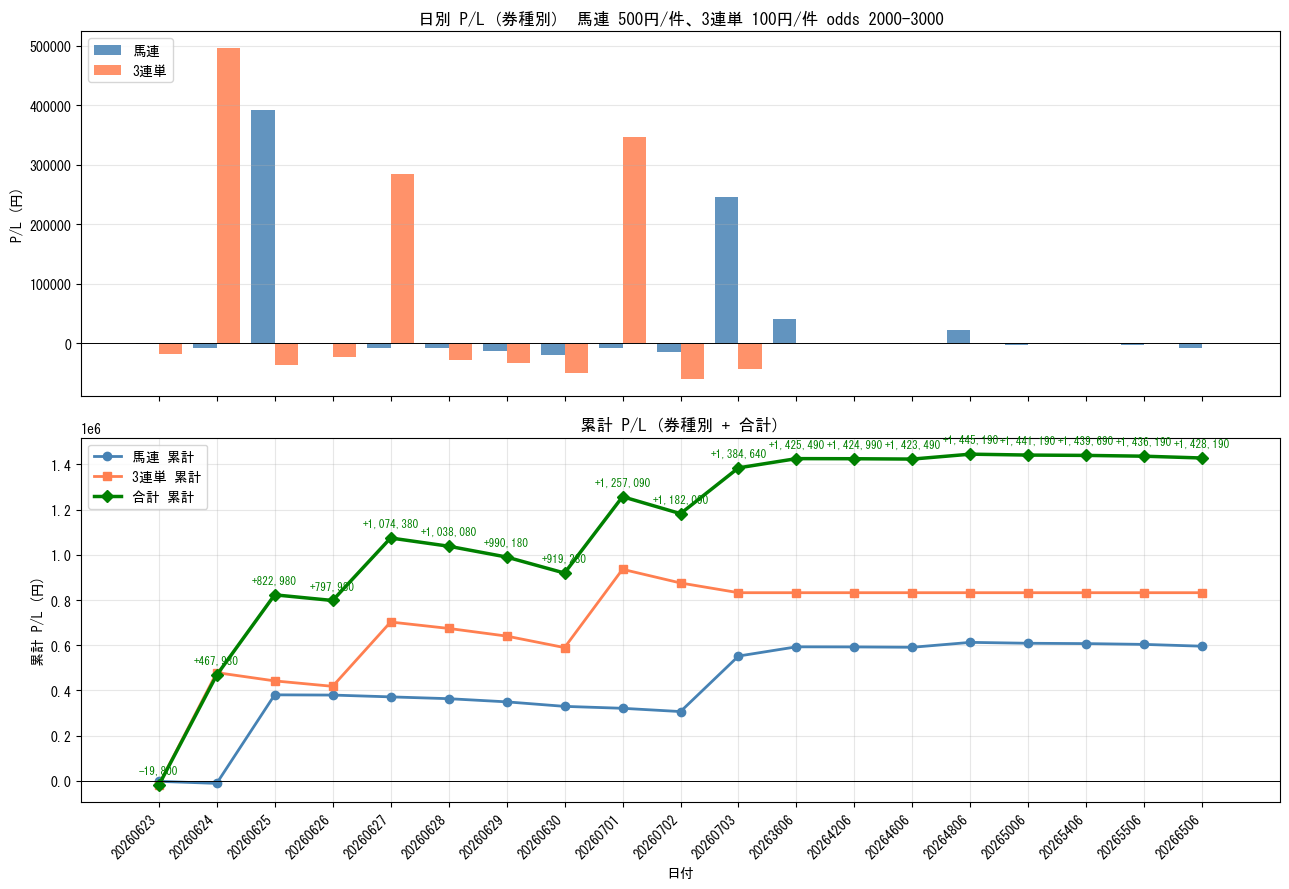

In [23]:
# ════════════════════════════════════════════════════════════
# 日別 P/L グラフ (券種別 bar + 累計線)
# ════════════════════════════════════════════════════════════
import matplotlib.pyplot as plt
import matplotlib
# Windows 日本語フォント (MS Gothic) — 環境に合わせて変更可
try:
    matplotlib.rcParams['font.family'] = 'MS Gothic'
except Exception:
    pass
matplotlib.rcParams['axes.unicode_minus'] = False

# pivot: index=race_date, columns=券種, values=pl
pivot_pl = pd.DataFrame({
    '馬連':   daily_uma[('馬連', 'pl')],
    '3連単':  daily_san[('3連単', 'pl')],
}).fillna(0).astype(int)
pivot_pl['合計'] = pivot_pl['馬連'] + pivot_pl['3連単']

fig, axes = plt.subplots(2, 1, figsize=(13, 9), sharex=True)

# (1) 日別 P/L bar (券種別 並列)
ax = axes[0]
x = range(len(pivot_pl))
w = 0.4
ax.bar([i - w/2 for i in x], pivot_pl['馬連'],  width=w, label='馬連',  color='steelblue', alpha=0.85)
ax.bar([i + w/2 for i in x], pivot_pl['3連単'], width=w, label='3連単', color='coral',     alpha=0.85)
ax.axhline(0, color='black', linewidth=0.7)
ax.set_title(f'日別 P/L (券種別)  馬連 {UMA_STAKE}円/件、3連単 {SAN_STAKE}円/件 odds {int(SAN_LO)}-{int(SAN_HI)}')
ax.set_ylabel('P/L (円)')
ax.set_xticks(list(x))
ax.set_xticklabels(pivot_pl.index, rotation=45, ha='right')
ax.grid(True, alpha=0.3, axis='y')
ax.legend(loc='upper left')

# (2) 累計 P/L line
ax = axes[1]
pivot_cum = pivot_pl.cumsum()
ax.plot(range(len(pivot_cum)), pivot_cum['馬連'],   marker='o', label='馬連 累計',  color='steelblue', linewidth=2)
ax.plot(range(len(pivot_cum)), pivot_cum['3連単'],  marker='s', label='3連単 累計', color='coral',     linewidth=2)
ax.plot(range(len(pivot_cum)), pivot_cum['合計'],   marker='D', label='合計 累計',  color='green',     linewidth=2.5)
ax.axhline(0, color='black', linewidth=0.7)
ax.set_title('累計 P/L (券種別 + 合計)')
ax.set_ylabel('累計 P/L (円)')
ax.set_xlabel('日付')
ax.set_xticks(list(range(len(pivot_cum))))
ax.set_xticklabels(pivot_cum.index, rotation=45, ha='right')
ax.grid(True, alpha=0.3)
ax.legend(loc='upper left')

# 各 marker に金額を表示
for i, (d, v) in enumerate(pivot_cum['合計'].items()):
    ax.annotate(f'{int(v):+,}', (i, v), textcoords='offset points', xytext=(0, 8),
                ha='center', fontsize=8, color='green')

plt.tight_layout()
plt.show()
